# 🏗️ ALGORITMO PLANTILLA DE ANÁLISIS ESTRUCTURAL APLICADO (NSR-10)
### Automatización de Memorias de Cálculo y Modelado en SAP2000
**Autor:** Nicolas Infante Hernandez | Ingeniería Civil  
---
### 📌 ¿Cómo usar?

1. **Cambiar datos:** En las celdas marcadas como **`PANEL DEL DISEÑADOR`**, modifica los valores entre comillas o los números según tu proyecto.
2. **Correr en orden:** cada bloque usa variables de los anteriores; ejecuta de arriba hacia abajo.
3. **Ver resultados:** Las tablas resultantes están listas para copiar a tus memorias de cálculo y los parámetros a SAP2000.


### 🧭 Flujo completo
1–2. Sismo y predimensionamiento de losa · 3. Cargas (Título B) · 4. Pesos por nivel · 5. FHE (A.4) · 6. Espectro para SAP2000 · 7. Derivas (A.6) · 8. Irregularidades y R (A.3.3) · 9. Combinaciones (B.2.4) · 10. Verificación modal (A.5) · 11. Resumen y registro para el ML

Los bloques 7, 8 y 10 necesitan resultados de SAP2000. Traen **valores de ejemplo** marcados con `DATOS_SAP_SON_EJEMPLO = True` hasta que pegues los de tu modelo.


## 📍 BLOQUE 1: DEFINICIÓN GEOTÉCNICA, SÍSMICA Y GRUPO DE USO (NSR-10 A.2)
En la siguiente celda tienes el **Panel de Entrada**.
└─► Eliges ciudad, suelo y uso. Obtienes espectro y Sa_max.


In [1]:
# ==============================================================================
# 1. PANEL DE CONTROL DEL DISEÑADOR (MODIFICAR PARÁMETROS)
# ==============================================================================
DATOS_PROYECTO_BLOQUE_1 = {
    # Escribe la ciudad capital (ej: "Cúcuta", "Bogotá", "Medellín", "Cali", "Bucaramanga", etc.)
    # Si tienes un estudio particular con Aa y Av propios, escribe "PERSONALIZADO"
    "ciudad": "Cúcuta",

    # Tipo de perfil de suelo según estudio geotécnico ('A', 'B', 'C', 'D', 'E')
    "tipo_suelo": "D",

    # Grupo de Uso según NSR-10 A.2.5:
    # 1: Ocupación normal (vivienda, oficinas)                               -> I = 1.00
    # 2: Ocupación especial (reunión de > 200 personas, comercio > 500 m²/piso) -> I = 1.10
    # 3: Atención a la comunidad (colegios, universidades, policía, bomberos)  -> I = 1.25
    # 4: Indispensables (hospitales con cirugía/urgencias, centrales esenciales) -> I = 1.50
    "grupo_uso": 1,

    # Solo se usan si arriba pusiste "ciudad": "PERSONALIZADO":
    #"Aa_personalizado": 0.35, -> Quitar comment
    #"Av_personalizado": 0.30,
}

print("✓ Parámetros iniciales cargados correctamente:")
for k, v in DATOS_PROYECTO_BLOQUE_1.items():
    print(f"  - {k}: {v}")


✓ Parámetros iniciales cargados correctamente:
  - ciudad: Cúcuta
  - tipo_suelo: D
  - grupo_uso: 1


In [2]:
# ==============================================================================
# MOTOR DE CÁLCULO DEL BLOQUE 1 (BASE DE DATOS NSR-10 E INTERPOLACIONES)
# ==============================================================================
import math
import pandas as pd

TABLA_CAPITALES_NSR10 = {
    "Arauca": {"Aa": 0.15, "Av": 0.15, "Zona": "Intermedia"},
    "Armenia": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Barranquilla": {"Aa": 0.10, "Av": 0.10, "Zona": "Baja"},
    "Bogotá": {"Aa": 0.15, "Av": 0.20, "Zona": "Intermedia"},
    "Bucaramanga": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Cali": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Cartagena": {"Aa": 0.10, "Av": 0.10, "Zona": "Baja"},
    "Cúcuta": {"Aa": 0.35, "Av": 0.30, "Zona": "Alta"},
    "Florencia": {"Aa": 0.20, "Av": 0.15, "Zona": "Intermedia"},
    "Ibagué": {"Aa": 0.20, "Av": 0.20, "Zona": "Intermedia"},
    "Manizales": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Medellín": {"Aa": 0.15, "Av": 0.20, "Zona": "Intermedia"},
    "Mocoa": {"Aa": 0.30, "Av": 0.25, "Zona": "Alta"},
    "Montería": {"Aa": 0.10, "Av": 0.15, "Zona": "Intermedia"},
    "Neiva": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Pasto": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Pereira": {"Aa": 0.25, "Av": 0.25, "Zona": "Alta"},
    "Popayán": {"Aa": 0.25, "Av": 0.20, "Zona": "Alta"},
    "Quibdó": {"Aa": 0.35, "Av": 0.35, "Zona": "Alta"},
    "Riohacha": {"Aa": 0.10, "Av": 0.15, "Zona": "Intermedia"},
    "San Andrés": {"Aa": 0.10, "Av": 0.10, "Zona": "Baja"},
    "Santa Marta": {"Aa": 0.15, "Av": 0.10, "Zona": "Intermedia"},
    "Sincelejo": {"Aa": 0.10, "Av": 0.15, "Zona": "Intermedia"},
    "Tunja": {"Aa": 0.20, "Av": 0.20, "Zona": "Intermedia"},
    "Valledupar": {"Aa": 0.10, "Av": 0.10, "Zona": "Baja"},
    "Villavicencio": {"Aa": 0.35, "Av": 0.30, "Zona": "Alta"},
    "Yopal": {"Aa": 0.30, "Av": 0.20, "Zona": "Alta"}
}

class Bloque1SismicaGeotecnia:
    def __init__(self, entradas: dict):
        self.ciudad = entradas["ciudad"]
        self.tipo_suelo = entradas["tipo_suelo"].upper()
        self.grupo_uso = entradas["grupo_uso"]

        if self.ciudad.upper() == "PERSONALIZADO":
            self.Aa = entradas["Aa_personalizado"]
            self.Av = entradas["Av_personalizado"]
            self.zona = "Personalizada / Microzonificación"
        else:
            datos = TABLA_CAPITALES_NSR10.get(self.ciudad)
            if not datos:
                raise ValueError(f"Ciudad '{self.ciudad}' no encontrada. Usa 'PERSONALIZADO'.")
            self.Aa = datos["Aa"]
            self.Av = datos["Av"]
            self.zona = datos["Zona"]

        self.I = self._coef_importancia()
        self.Fa = self._interpolar_Fa()
        self.Fv = self._interpolar_Fv()

    def _coef_importancia(self) -> float:
        return {1: 1.00, 2: 1.10, 3: 1.25, 4: 1.50}.get(self.grupo_uso, 1.00)

    def _interpolar_Fa(self) -> float:
        pts = [0.10, 0.20, 0.30, 0.40, 0.50]
        tabla = {
            'A': [0.8, 0.8, 0.8, 0.8, 0.8],
            'B': [1.0, 1.0, 1.0, 1.0, 1.0],
            'C': [1.2, 1.2, 1.1, 1.0, 1.0],
            'D': [1.6, 1.4, 1.2, 1.1, 1.0],
            'E': [2.5, 1.7, 1.2, 0.9, 0.9]
        }
        v = tabla[self.tipo_suelo]
        if self.Aa <= pts[0]: return v[0]
        if self.Aa >= pts[-1]: return v[-1]
        for i in range(len(pts)-1):
            if pts[i] <= self.Aa <= pts[i+1]:
                t = (self.Aa - pts[i]) / (pts[i+1] - pts[i])
                return round(v[i] + t * (v[i+1] - v[i]), 3)

    def _interpolar_Fv(self) -> float:
        pts = [0.10, 0.20, 0.30, 0.40, 0.50]
        tabla = {
            'A': [0.8, 0.8, 0.8, 0.8, 0.8],
            'B': [1.0, 1.0, 1.0, 1.0, 1.0],
            'C': [1.7, 1.6, 1.5, 1.4, 1.3],
            'D': [2.4, 2.0, 1.8, 1.6, 1.5],
            'E': [3.5, 3.2, 2.8, 2.4, 2.4]
        }
        v = tabla[self.tipo_suelo]
        if self.Av <= pts[0]: return v[0]
        if self.Av >= pts[-1]: return v[-1]
        for i in range(len(pts)-1):
            if pts[i] <= self.Av <= pts[i+1]:
                t = (self.Av - pts[i]) / (pts[i+1] - pts[i])
                return round(v[i] + t * (v[i+1] - v[i]), 3)

    def periodos_espectro(self) -> dict:
        T0 = 0.10 * (self.Av * self.Fv) / (self.Aa * self.Fa)
        Tc = 0.48 * (self.Av * self.Fv) / (self.Aa * self.Fa)
        TL = 2.40 * self.Fv
        return {'T0': round(T0, 4), 'Tc': round(Tc, 4), 'TL': round(TL, 4)}

    def tabla_memoria(self) -> pd.DataFrame:
        return pd.DataFrame([
            {"Parámetro": "Ciudad", "Símbolo": "-", "Valor": self.ciudad},
            {"Parámetro": "Zona de Amenaza Sísmica", "Símbolo": "-", "Valor": self.zona},
            {"Parámetro": "Perfil del suelo", "Símbolo": "-", "Valor": self.tipo_suelo},
            {"Parámetro": "Grupo de Uso", "Símbolo": "-", "Valor": f"Grupo {self.grupo_uso}"},
            {"Parámetro": "Coeficiente de importancia", "Símbolo": "I", "Valor": self.I},
            {"Parámetro": "Aceleración pico efectiva", "Símbolo": "Aa", "Valor": self.Aa},
            {"Parámetro": "Velocidad pico efectiva", "Símbolo": "Av", "Valor": self.Av},
            {"Parámetro": "Coeficiente periodos cortos", "Símbolo": "Fa", "Valor": self.Fa},
            {"Parámetro": "Coeficiente periodos intermedios", "Símbolo": "Fv", "Valor": self.Fv},
        ])

    def valores_sap2000(self) -> dict:
        p = self.periodos_espectro()
        return {
            "Función Espectro en SAP2000": "NSR-10 / User Defined",
            "Aa": self.Aa,
            "Av": self.Av,
            "Fa": self.Fa,
            "Fv": self.Fv,
            "I": self.I,
            "T0 (s)": p["T0"],
            "Tc (s)": p["Tc"],
            "TL (s)": p["TL"],
            "Sa_max (Meseta) [g]": round(2.5 * self.Aa * self.Fa * self.I, 5)
        }

# Ejecución del Bloque 1
b1 = Bloque1SismicaGeotecnia(DATOS_PROYECTO_BLOQUE_1)

print("=======================================================================")
print("TABLA DE REQUERIMIENTOS SÍSMICOS (PARA LA MEMORIA DE CÁLCULO)")
print("=======================================================================")
print(b1.tabla_memoria().to_string(index=False))

print("\n=======================================================================")
print("PARÁMETROS PARA SAP2000 (DEFINE > FUNCTIONS > RESPONSE SPECTRUM)")
print("=======================================================================")
for k, v in b1.valores_sap2000().items():
    print(f"  {k:35} : {v}")


TABLA DE REQUERIMIENTOS SÍSMICOS (PARA LA MEMORIA DE CÁLCULO)
                       Parámetro Símbolo   Valor
                          Ciudad       -  Cúcuta
         Zona de Amenaza Sísmica       -    Alta
                Perfil del suelo       -       D
                    Grupo de Uso       - Grupo 1
      Coeficiente de importancia       I     1.0
       Aceleración pico efectiva      Aa    0.35
         Velocidad pico efectiva      Av     0.3
     Coeficiente periodos cortos      Fa    1.15
Coeficiente periodos intermedios      Fv     1.8

PARÁMETROS PARA SAP2000 (DEFINE > FUNCTIONS > RESPONSE SPECTRUM)
  Función Espectro en SAP2000         : NSR-10 / User Defined
  Aa                                  : 0.35
  Av                                  : 0.3
  Fa                                  : 1.15
  Fv                                  : 1.8
  I                                   : 1.0
  T0 (s)                              : 0.1342
  Tc (s)                              : 0.644
  TL 

---
## 📏 BLOQUE 2: PREDIMENSIONAMIENTO DE LOSA Y MODULACIÓN DE VIGUETAS
En este bloque se analizan todas las viguetas tramo por tramo con las tablas **C.9.5(a)** y **CR.9.5** de la NSR-10, y se genera la modulación de nervios en dirección X (descontando el ancho de las vigas de rigidez `b_vr = 0.40 m`).

└─► Comparas X vs Y, predimensionas Hlosa y bvt. Seleccionas Sl y Sv.


✓ Geometría de viguetas en Y y en X cargada correctamente.



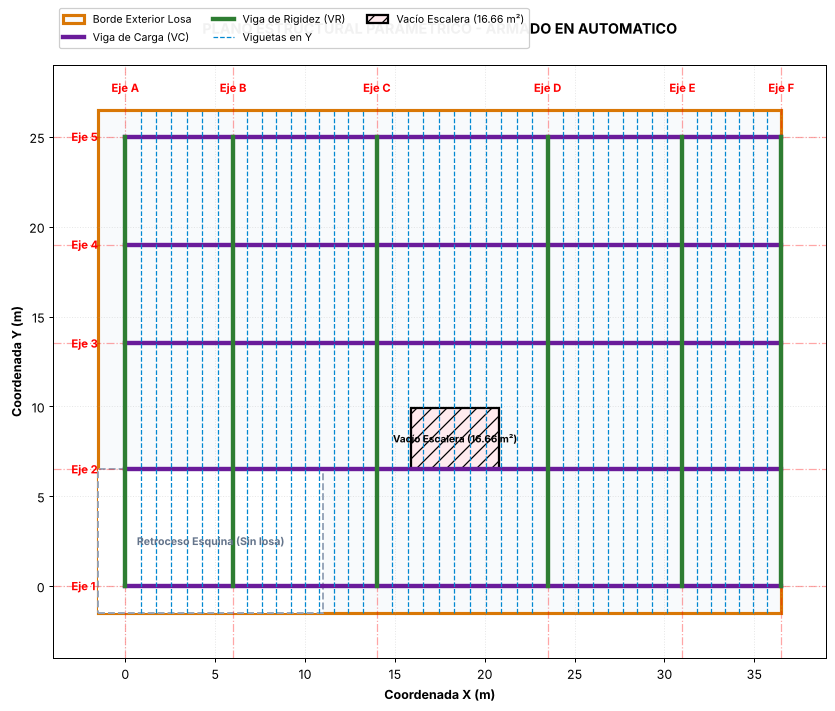

In [3]:
# ==============================================================================
# 2. PANEL DEL DISEÑADOR: ELECCIÓN DE ARMADO, VIGUETAS EN Y / X Y PAÑOS
#
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

# 1. Dirección de armado: 'AUTOMATICO' (el código evalúa y decide), 'Y' o 'X'
DIRECCION_ARMADO = 'AUTOMATICO'

# 2. Viguetas en Y a evaluar tramo a tramo (NSR-10 C.9.5a / CR.9.5):
VIGUETAS_Y = {
    'VTy1': [{'luz': 7.0, 'apoyo': '1EC'}, {'luz': 5.5, 'apoyo': '2EC'}, {'luz': 6.0, 'apoyo': '2EC'}, {'luz': 1.5, 'apoyo': 'VOL'}],
    'VTy2': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.5, 'apoyo': '2EC'}, {'luz': 7.0, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '2EC'}, {'luz': 6.0, 'apoyo': '2EC'}, {'luz': 1.5, 'apoyo': 'VOL'}],
    'VTy3': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.5, 'apoyo': '2EC'}, {'luz': 3.4, 'apoyo': '2EC'}, {'luz': 3.6, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '2EC'}, {'luz': 6.0, 'apoyo': '1EC'}],
    'VTy4': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.5, 'apoyo': '1EC'}],
    'VTy5': [{'luz': 3.6, 'apoyo': '1EC'}, {'luz': 5.5, 'apoyo': '2EC'}, {'luz': 6.0, 'apoyo': '1EC'}],
    'VTy6': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.5, 'apoyo': '2EC'}, {'luz': 7.0, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '2EC'}, {'luz': 6.0, 'apoyo': '1EC'}]
}

# 3. Viguetas en X actualizadas para la comparativa:
VIGUETAS_X = {
    'VTx1': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.0, 'apoyo': '1EC'}, {'luz': 8.0, 'apoyo': '2EC'}, {'luz': 9.5, 'apoyo': '2EC'}, {'luz': 7.5, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '1EC'}],
    'VTx2': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.0, 'apoyo': '1EC'}, {'luz': 8.0, 'apoyo': '2EC'}, {'luz': 9.5, 'apoyo': '2EC'}, {'luz': 7.5, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '1EC'}],
    'VTx3': [{'luz': 1.5, 'apoyo': 'VOL'}, {'luz': 6.0, 'apoyo': '2EC'}, {'luz': 8.0, 'apoyo': '2EC'}, {'luz': 5.5, 'apoyo': '2EC'}]
}

# 4. Paños entre ejes estructurales (agrega o quita los ejes que tenga tu proyecto):
PANOS_EJES_X = {
    'Eje A-B': 6.0, 'Eje B-C': 8.0, 'Eje C-D': 9.5, 'Eje D-E': 7.5, 'Eje E-F': 5.5
}
PANOS_EJES_Y = {
    'Eje 1-2': 6.5, 'Eje 2-3': 7.0, 'Eje 3-4': 5.5, 'Eje 4-5': 6.0
}
ANCHO_VIGA_RIGIDEZ = 0.40   # Ancho de las vigas de rigidez VR en metros (40 cm)

# 5. Geometría exterior parametrizada (Voladizos, retrocesos y vacíos):
VOLADIZOS_EXTERIORES = {'izq': 1.50, 'der': 0.00, 'sup': 1.50, 'inf': 1.50}
RETROCESOS_PLANTA = [
    {'x': -1.50, 'y': -1.50, 'ancho': 12.50, 'largo': 8.00, 'nombre': 'Retroceso Esquina (Sin losa)'}
]
HUECOS_VACIOS = [
    {'x': 15.90, 'y': 6.50, 'ancho': 4.90, 'largo': 3.40, 'nombre': 'Vacío Escalera (16.66 m²)'}
]

print('✓ Geometría de viguetas en Y y en X cargada correctamente.\n')

# Visualizador genérico aun en prueba
def graficar_planta_generica(panos_x, panos_y, voladizos, retrocesos, huecos, direccion):
    fig, ax = plt.subplots(figsize=(12, 8))
    x_coords = [0.0]
    for k in panos_x: x_coords.append(x_coords[-1] + panos_x[k])
    y_coords = [0.0]
    for k in panos_y: y_coords.append(y_coords[-1] + panos_y[k])

    x_min, x_max = x_coords[0] - voladizos.get('izq', 0.0), x_coords[-1] + voladizos.get('der', 0.0)
    y_min, y_max = y_coords[0] - voladizos.get('inf', 0.0), y_coords[-1] + voladizos.get('sup', 0.0)

    rect_losa = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                  facecolor='#f8fafc', edgecolor='#d97706', lw=2.5, label='Borde Exterior Losa')
    ax.add_patch(rect_losa)

    for ret in retrocesos:
        r = patches.Rectangle((ret['x'], ret['y']), ret['ancho'], ret['largo'], facecolor='white', edgecolor='#94a3b8', linestyle='--', lw=1.5)
        ax.add_patch(r)
        ax.text(ret['x'] + ret['ancho']/2, ret['y'] + ret['largo']/2, ret.get('nombre', ''), ha='center', va='center', color='#64748b', fontsize=8.5, fontweight='bold')

    for i, x in enumerate(x_coords):
        ax.axvline(x, color='red', linestyle='-.', alpha=0.35, lw=1)
        ax.text(x, y_max + 1.0, f'Eje {chr(65+i)}', color='red', ha='center', fontweight='bold', fontsize=9)
    for j, y in enumerate(y_coords):
        ax.axhline(y, color='red', linestyle='-.', alpha=0.35, lw=1)
        ax.text(x_min - 1.5, y, f'Eje {j+1}', color='red', va='center', fontweight='bold', fontsize=9)

    for y in y_coords: ax.plot([x_coords[0], x_coords[-1]], [y, y], color='#6a1b9a', lw=3.5, label='Viga de Carga (VC)' if (y==y_coords[0] and direccion in ['Y', 'AUTOMATICO']) else '')
    for x in x_coords: ax.plot([x, x], [y_coords[0], y_coords[-1]], color='#2e7d32', lw=3.5, label='Viga de Rigidez (VR)' if (x==x_coords[0] and direccion in ['Y', 'AUTOMATICO']) else '')

    if direccion.upper() in ['Y', 'AUTOMATICO']:
        for i in range(len(x_coords)-1):
            dx = x_coords[i+1] - x_coords[i]
            nvtas = max(2, int(dx / 0.87))
            sp = dx / (nvtas + 1)
            for v in range(1, nvtas + 1):
                xv = x_coords[i] + v * sp
                ax.plot([xv, xv], [y_min, y_max], color='#0288d1', lw=1.0, linestyle='--', label='Viguetas en Y' if (i==0 and v==1) else '')

    for h in huecos:
        hp = patches.Rectangle((h['x'], h['y']), h['ancho'], h['largo'], facecolor='#ffebee', edgecolor='black', hatch='//', lw=1.8, label=h.get('nombre', 'Vacío'))
        ax.add_patch(hp)
        ax.text(h['x'] + h['ancho']/2, h['y'] + h['largo']/2, h.get('nombre', 'VACÍO'), ha='center', va='center', fontsize=8, fontweight='bold')

    ax.set_title(f'PLANO ESTRUCTURAL PARAMÉTRICO - ARMADO EN {direccion.upper()}', fontsize=11.5, fontweight='bold', pad=25)
    ax.set_xlim(x_min - 2.5, x_max + 2.5)
    ax.set_ylim(y_min - 2.5, y_max + 2.5)
    ax.set_aspect('equal')
    ax.set_xlabel('Coordenada X (m)', fontweight='bold')
    ax.set_ylabel('Coordenada Y (m)', fontweight='bold')
    ax.legend(loc='lower left', bbox_to_anchor=(0.0, 1.02), ncol=3, fontsize=8.5, framealpha=0.95)
    ax.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.show()

graficar_planta_generica(PANOS_EJES_X, PANOS_EJES_Y, VOLADIZOS_EXTERIORES, RETROCESOS_PLANTA, HUECOS_VACIOS, direccion=DIRECCION_ARMADO)

In [4]:
# ==============================================================================
# MOTOR DE CÁLCULO DEL BLOQUE 2: COMPARATIVA X vs Y Y TABLA SVt (PRIMEROS 10 N_vtas)
# Celda: CXTScSdN3OoX
# ==============================================================================
import math
import pandas as pd
from typing import Tuple, Dict, List

class Bloque2Predimensionamiento:
    def __init__(self):
        self.div_c95a = {'1EC': 18.5, '2EC': 21.0, 'VOL': 8.0, 'SA': 16.0}
        self.div_cr95 = {'1EC': 12.0, '2EC': 14.0, 'VOL': 5.0, 'SA': 11.0}

    def evaluar_conjunto_viguetas(self, viguetas_dict: dict) -> Tuple[float, float, float, pd.DataFrame]:
        registros = []
        max_h = 0.0
        max_luz = 0.0
        for vig_nombre, tramos in viguetas_dict.items():
            for i, tramo in enumerate(tramos, 1):
                luz = tramo['luz']
                apoyo = tramo['apoyo']
                hc95 = luz / self.div_c95a[apoyo]
                hcr95 = luz / self.div_cr95[apoyo]
                hcrit = max(hc95, hcr95)
                max_h = max(max_h, hcrit)
                max_luz = max(max_luz, luz)
                registros.append({
                    'Vigueta': vig_nombre, 'Tramo': i, 'Luz (m)': luz, 'Apoyo': apoyo,
                    'h C.9.5(a)': round(hc95, 3), 'h CR.9.5': round(hcr95, 3), 'h Crítico (m)': round(hcrit, 3)
                })
        h_losa = math.ceil(max_h * 20.0) / 20.0
        b_vt = max(0.10, round(h_losa / 5.0, 2))
        return h_losa, b_vt, max_luz, pd.DataFrame(registros)

    def comparar_direcciones(self, vig_y: dict, vig_x: dict) -> dict:
        hy, by, max_ly, df_y = self.evaluar_conjunto_viguetas(vig_y)
        hx, bx, max_lx, df_x = self.evaluar_conjunto_viguetas(vig_x)
        demanda_y = max_ly ** 2
        demanda_x = max_lx ** 2
        if hy < hx:
            recomendada = 'Y'
            ahorro = round((1.0 - (demanda_y / demanda_x)) * 100.0, 1)
            justificacion = (f'Se recomienda armar en Y: requiere Hlosa = {hy:.2f} m frente a {hx:.2f} m en X. '
                             f'La demanda de momento flector crítico en Y es {ahorro}% menor, '
                             f'optimizando el peso propio de la losa y reduciendo el acero de refuerzo.')
        elif hx < hy:
            recomendada = 'X'
            ahorro = round((1.0 - (demanda_x / demanda_y)) * 100.0, 1)
            justificacion = (f'Se recomienda armar en X: requiere Hlosa = {hx:.2f} m frente a {hy:.2f} m en Y. '
                             f'La demanda de momento flector crítico en X es {ahorro}% menor.')
        else:
            recomendada = 'Y' if demanda_y <= demanda_x else 'X'
            justificacion = f'Ambas direcciones requieren Hlosa = {hy:.2f} m. Se adopta {recomendada} por menor luz crítica.'

        return {
            'direccion_recomendada': recomendada, 'justificacion': justificacion,
            'hy': hy, 'by': by, 'max_ly': max_ly, 'df_y': df_y,
            'hx': hx, 'bx': bx, 'max_lx': max_lx, 'df_x': df_x
        }

    def modular_nervios_primeros_10(self, panos: dict, b_vr: float, b_vt: float) -> pd.DataFrame:
        filas = []
        for n in range(2, 12):  # Primeros 10 valores de N_vtas: 2 a 11
            fila = {'N_vtas': n}
            for pano, luz in panos.items():
                sl_vr = luz - b_vr
                sl = (sl_vr - (n * b_vt)) / (n + 1)
                fila[f'{pano} Sl'] = round(sl, 3)
                fila[f'{pano} Sv'] = round(sl + b_vt, 3)
            filas.append(fila)
        return pd.DataFrame(filas)

b2 = Bloque2Predimensionamiento()
comp = b2.comparar_direcciones(VIGUETAS_Y, VIGUETAS_X)

if DIRECCION_ARMADO.upper() == 'AUTOMATICO':
    dir_final = comp['direccion_recomendada']
else:
    dir_final = DIRECCION_ARMADO.upper()

if dir_final == 'Y':
    hlosa_global = comp['hy']
    bvt_global = comp['by']
    df_viguetas_final = comp['df_y']
    panos_modular = PANOS_EJES_X
else:
    hlosa_global = comp['hx']
    bvt_global = comp['bx']
    df_viguetas_final = comp['df_x']
    panos_modular = PANOS_EJES_Y

df_svt_10 = b2.modular_nervios_primeros_10(panos_modular, b_vr=ANCHO_VIGA_RIGIDEZ, b_vt=bvt_global)

print('=' * 95)
print('⚖️  COMPARATIVA TÉCNICA DE DIRECCIÓN DE ARMADO (X vs Y):')
print('=' * 95)
print(f'  • Vigueta en Y crítica: Luz máx = {comp["max_ly"]} m  --> Hlosa requerida = {comp["hy"]} m (60 cm)')
print(f'  • Vigueta en X crítica: Luz máx = {comp["max_lx"]} m  --> Hlosa requerida = {comp["hx"]} m (70 cm)')
print(f'\n📢 DICTAMEN: {comp["direccion_recomendada"]}')
print(f'📝 JUSTIFICACIÓN: {comp["justificacion"]}')
print(f'\n⚙️  MODO ELEGIDO: {DIRECCION_ARMADO} --> Se adopta ARMADO EN {dir_final}')
print(f'   - Hlosa crítico adoptado : {hlosa_global} m')
print(f'   - bvt base vigueta       : {bvt_global} m')
print('=' * 95)

print(f'\n1. TABLA DETALLADA TRAMO A TRAMO PARA ARMADO EN {dir_final} (PRIMEROS 10 TRAMOS):')
print(df_viguetas_final.head(10).to_string(index=False))

print(f'\n2. MATRIZ DE MODULACIÓN DE PAÑOS (HOJA SVt DE V7.xlsx - PRIMEROS 10 N_vtas):')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_svt_10.to_string(index=False))
print('\n👉 INSPECCIONA LA TABLA DE ARRIBA: Elige el valor de Sl más repetido/similar entre columnas y pásalo a la siguiente celda.')

⚖️  COMPARATIVA TÉCNICA DE DIRECCIÓN DE ARMADO (X vs Y):
  • Vigueta en Y crítica: Luz máx = 7.0 m  --> Hlosa requerida = 0.6 m (60 cm)
  • Vigueta en X crítica: Luz máx = 9.5 m  --> Hlosa requerida = 0.7 m (70 cm)

📢 DICTAMEN: Y
📝 JUSTIFICACIÓN: Se recomienda armar en Y: requiere Hlosa = 0.60 m frente a 0.70 m en X. La demanda de momento flector crítico en Y es 45.7% menor, optimizando el peso propio de la losa y reduciendo el acero de refuerzo.

⚙️  MODO ELEGIDO: AUTOMATICO --> Se adopta ARMADO EN Y
   - Hlosa crítico adoptado : 0.6 m
   - bvt base vigueta       : 0.12 m

1. TABLA DETALLADA TRAMO A TRAMO PARA ARMADO EN Y (PRIMEROS 10 TRAMOS):
Vigueta  Tramo  Luz (m) Apoyo  h C.9.5(a)  h CR.9.5  h Crítico (m)
   VTy1      1      7.0   1EC       0.378     0.583          0.583
   VTy1      2      5.5   2EC       0.262     0.393          0.393
   VTy1      3      6.0   2EC       0.286     0.429          0.429
   VTy1      4      1.5   VOL       0.188     0.300          0.300
   VTy2     

In [5]:
# ==============================================================================
# 3. PANEL DE SELECCIÓN DE ALIGERAMIENTO (TRAS REVISAR LA TABLA SVt)
# ==============================================================================

# 1. Elige e ingresa el Sl representativo que más se parezca entre paños (en metros):
SL_ADOPTADO = 0.75          # En V7.xlsx se adoptó Sl = 0.75 m (casetón de 75 cm)

# 2. Altura de loseta inferior (en metros):
# Si es casetón removible (como en tu proyecto V7), escribe 0.00.
# Si es losa con loseta inferior permanente de concreto, escribe su espesor (ej: 0.025 m).
HLI_LOSA = 0.00

# ==============================================================================
# VERIFICACIÓN NORMATIVA DE LOSETAS Y CASETONES (NSR-10 C.8.13.6)
# ==============================================================================
sl_sobre_20 = round(SL_ADOPTADO / 20.0, 4)
print(f'• Sl ingresado por el diseñador : {SL_ADOPTADO} m ({SL_ADOPTADO*100:.1f} cm)')
print(f'• Relación Sl / 20              : {sl_sobre_20} m ({sl_sobre_20*100:.2f} cm)')

# Verificación estricta NSR-10 C.8.13.6.1:
# hls >= max(0.045 m, Sl / 20)
if sl_sobre_20 < 0.045:
    print(f'  ⚠️ [NOTIFICACIÓN NSR-10 C.8.13.6.1]: Sl/20 ({sl_sobre_20*100:.2f} cm) es menor a 4.5 cm (0.045 m).')
    print('     Por norma rige el mínimo de 0.045 m y constructivamente se asigna hls = 0.05 m (5 cm).')
    hls_final = 0.05
else:
    hls_calc = math.ceil(sl_sobre_20 * 100.0) / 100.0
    hls_final = max(0.05, hls_calc)
    print(f'  ✓ [CUMPLE]: Sl/20 ({sl_sobre_20} m) rige. Se asigna loseta superior hls = {hls_final} m.')

# Altura neta del casetón y separación centro a centro:
# hcas = hvt - hls - hli
hvt_final = hlosa_global
hcas_final = round(hvt_final - hls_final - HLI_LOSA, 3)
sv_final = round(SL_ADOPTADO + bvt_global, 3)

parametros_aligeramiento = {
    'hvt (Altura total de losa) [m]': hvt_final,
    'bvt (Base de vigueta/nervio) [m]': bvt_global,
    'Sl (Ancho libre de casetón) [m]': SL_ADOPTADO,
    'Sv (Separación centro a centro) [m]': sv_final,
    'hls (Espesor loseta superior) [m]': hls_final,
    'hli (Espesor loseta inferior) [m]': HLI_LOSA,
    'hcas (Altura neta de casetón) [m]': hcas_final,
    'Límite Sl/20 [m]': sl_sobre_20
}

print('\n' + '=' * 75)
print('PARÁMETROS DEFINITIVOS DE ALIGERAMIENTO (HOJA FHE DE V7.xlsx):')
print('=' * 75)
for k, v in parametros_aligeramiento.items():
    print(f'  • {k:38} : {v}')

• Sl ingresado por el diseñador : 0.75 m (75.0 cm)
• Relación Sl / 20              : 0.0375 m (3.75 cm)
  ⚠️ [NOTIFICACIÓN NSR-10 C.8.13.6.1]: Sl/20 (3.75 cm) es menor a 4.5 cm (0.045 m).
     Por norma rige el mínimo de 0.045 m y constructivamente se asigna hls = 0.05 m (5 cm).

PARÁMETROS DEFINITIVOS DE ALIGERAMIENTO (HOJA FHE DE V7.xlsx):
  • hvt (Altura total de losa) [m]         : 0.6
  • bvt (Base de vigueta/nervio) [m]       : 0.12
  • Sl (Ancho libre de casetón) [m]        : 0.75
  • Sv (Separación centro a centro) [m]    : 0.87
  • hls (Espesor loseta superior) [m]      : 0.05
  • hli (Espesor loseta inferior) [m]      : 0.0
  • hcas (Altura neta de casetón) [m]      : 0.55
  • Límite Sl/20 [m]                       : 0.0375


---
## 📏 BLOQUE 3: ASIGNACIÓN DE CARGAS
Despliega en pantalla las 6 tablas normativas oficiales de la NSR-10

*   Tabla B.3.4.2-4 de Muros Verticales
*   Tabla B.3.4.1-2: Rellenos de piso
*   Tabla B.3.4.1-3: Pisos y acabados
*   Tabla B.3.4.1-1: Cielo raso
*   Tabla B.3.4.3-1: Muros divisorios por ocupación
*   Tabla B.4.2.1-1 y B.4.2.1-2: Cargas vivas mínimas

Areas, centroides y cargas


In [6]:
# ==============================================================================
# BLOQUE 3.1: CONSULTA DE TABLAS NSR-10 (TÍTULO B) Y AVALÚO DE CARGAS
# ==============================================================================
import pandas as pd

# ------------------------------------------------------------------------------
# CATÁLOGO Y DESPLIEGUE DE TABLAS NORMATIVAS NSR-10
# ------------------------------------------------------------------------------

# Tabla B.3.4.1-2: Rellenos de piso
TABLA_RELLENOS = pd.DataFrame([
    {"Material": "Concreto con escoria", "Carga (kN/m² por mm)": 0.0200, "Densidad (kg/m³)": 2000},
    {"Material": "Concreto con piedra",  "Carga (kN/m² por mm)": 0.0250, "Densidad (kg/m³)": 2500},
    {"Material": "Concreto ligero",      "Carga (kN/m² por mm)": 0.0150, "Densidad (kg/m³)": 1500},
    {"Material": "Arena",                "Carga (kN/m² por mm)": 0.0150, "Densidad (kg/m³)": 1500}
])

# Tabla B.3.4.1-3: Pisos y acabados
TABLA_PISOS = pd.DataFrame([
    {"Acabado": "Afinado (25 mm) sobre concreto",         "Carga (kN/m²)": 1.50},
    {"Acabado": "Terrazzo (40 mm) directamente sobre losa","Carga (kN/m²)": 0.90},
    {"Acabado": "Terrazzo (25 mm) sobre afinado",          "Carga (kN/m²)": 1.50},
    {"Acabado": "Baldosa cerámica (20 mm) mortero 12 mm",  "Carga (kN/m²)": 0.80},
    {"Acabado": "Baldosa cerámica (20 mm) mortero 25 mm",  "Carga (kN/m²)": 1.10},
    {"Acabado": "Mármol y mortero sobre concreto",         "Carga (kN/m²)": 1.60},
    {"Acabado": "Piso asfáltico o linóleo (6 mm)",         "Carga (kN/m²)": 0.05}
])

# Tabla B.3.4.1-1: Cielo raso
TABLA_CIELO = pd.DataFrame([
    {"Cielo Raso": "Entramado metálico suspendido afinado en cemento", "Carga (kN/m²)": 0.70},
    {"Cielo Raso": "Entramado metálico suspendido afinado en yeso",    "Carga (kN/m²)": 0.50},
    {"Cielo Raso": "Ductos mecánicos (base obligatoria)",             "Carga (kN/m²)": 0.20},
    {"Cielo Raso": "Canales suspendidas de acero",                     "Carga (kN/m²)": 0.10},
    {"Cielo Raso": "Pañete en yeso o concreto",                        "Carga (kN/m²)": 0.25}
])

# Tabla B.3.4.3-1: Muros divisorios por ocupación
TABLA_PARTICIONES = pd.DataFrame([
    {"Ocupación": "Oficinas - Particiones fijas de mampostería", "Carga (kN/m²)": 2.00},
    {"Ocupación": "Oficinas - Particiones móviles altura total", "Carga (kN/m²)": 1.00},
    {"Ocupación": "Residencial - Mampostería",                   "Carga (kN/m²)": 3.00},
    {"Ocupación": "Residencial - Particiones livianas",          "Carga (kN/m²)": 2.00},
    {"Ocupación": "Educativos - Salones de clase",               "Carga (kN/m²)": 2.00},
    {"Ocupación": "Comercio - Exhibición y venta",               "Carga (kN/m²)": 1.50}
])

# Tabla B.3.4.2-4: Muros verticales y antepechos por espesor (kN/m² de superficie)
TABLA_MUROS_VERTICALES = pd.DataFrame([
    {"Tipo de Muro": "Bloque arcilla pañetado 2 caras",      "100 mm": 1.80, "150 mm": 2.50, "200 mm": 3.10, "250 mm": 3.80},
    {"Tipo de Muro": "Bloque arcilla sin pañetar",           "100 mm": 1.30, "150 mm": 2.00, "200 mm": 2.60, "250 mm": 3.30},
    {"Tipo de Muro": "Bloque concreto sin relleno",          "100 mm": 1.40, "150 mm": 1.45, "200 mm": 1.90, "250 mm": 2.25},
    {"Tipo de Muro": "Macizo arcilla sin pañetar (antepecho)","100 mm": 1.90, "150 mm": 2.90, "200 mm": 3.80, "250 mm": 4.70}
])

# Tabla B.4.2.1-1 y B.4.2.1-2: Cargas vivas mínimas
TABLA_VIVAS = pd.DataFrame([
    {"Uso": "Oficinas - Corredores, escaleras y oficinas",   "Carga Viva (kN/m²)": 5.00},
    {"Uso": "Cubierta / Terraza - Reuniones y jardines",     "Carga Viva (kN/m²)": 5.00},
    {"Uso": "Restaurantes / Zonas de reunión",               "Carga Viva (kN/m²)": 5.00},
    {"Uso": "Residencial - Cuartos y corredores",            "Carga Viva (kN/m²)": 1.80},
    {"Uso": "Comercio - Minorista",                          "Carga Viva (kN/m²)": 5.00}
])

print("=" * 80)
print("TABLAS DE REFERENCIA NSR-10 (TÍTULO B) CARGADAS EN MEMORIA:")
print("=" * 80)
print("\n• TABLA B.3.4.1-2 (Rellenos de piso):")
print(TABLA_RELLENOS.to_string(index=False))
print("\n• TABLA B.3.4.1-3 (Pisos y acabados):")
print(TABLA_PISOS.head(4).to_string(index=False))
print("\n• TABLA B.3.4.2-4 (Muros verticales y antepechos por espesor):")
print(TABLA_MUROS_VERTICALES.to_string(index=False))


TABLAS DE REFERENCIA NSR-10 (TÍTULO B) CARGADAS EN MEMORIA:

• TABLA B.3.4.1-2 (Rellenos de piso):
            Material  Carga (kN/m² por mm)  Densidad (kg/m³)
Concreto con escoria                 0.020              2000
 Concreto con piedra                 0.025              2500
     Concreto ligero                 0.015              1500
               Arena                 0.015              1500

• TABLA B.3.4.1-3 (Pisos y acabados):
                                 Acabado  Carga (kN/m²)
          Afinado (25 mm) sobre concreto            1.5
Terrazzo (40 mm) directamente sobre losa            0.9
          Terrazzo (25 mm) sobre afinado            1.5
  Baldosa cerámica (20 mm) mortero 12 mm            0.8

• TABLA B.3.4.2-4 (Muros verticales y antepechos por espesor):
                          Tipo de Muro  100 mm  150 mm  200 mm  250 mm
       Bloque arcilla pañetado 2 caras     1.8    2.50     3.1    3.80
            Bloque arcilla sin pañetar     1.3    2.00     2.6    3.30


#BLOQUE 3A: Geometría de Planta y Centroides (AutoCAD LIST + Gauss)          │
 │   └─► Pegas LIST de AutoCAD. Obtienes Área neta de losa, Xcm, Ycm y plano 2D│

GEOMETRÍA Y CENTROIDES DE PLANTA (NSR-10 / HOJA Área losa DE V7.xlsx):
                       Elemento      Tipo  Vértices  Área [m²]  Cx [m]  Cy [m]  A * Cx [m³]  A * Cy [m³]
Perímetro Exterior (Área Total) Lleno (+)         6     938.50  20.009  12.378    18778.447    11616.753
       Hueco 1 (Vacío Escalera) Vacío (-)         4      16.66  20.850   8.500     -347.361     -141.610
-------------------------------------------------------------------------------------
• ÁREA NETA DE PLANTA (Columna Z: sin escalera) : 921.84 m²
• CENTROIDE GLOBAL DE MASA (Xcm, Ycm)          : Xcm = 19.994 m  |  Ycm = 12.448 m

📋 COPIA ESTE BLOQUE Y PÉGALO AL INICIO DE LA CELDA 3B:
DATOS_PLANTA_DESDE_BLOQUE_3A = {
    "A_bruta_losa": 921.84,
    "X_cm": 19.994,
    "Y_cm": 12.448
}


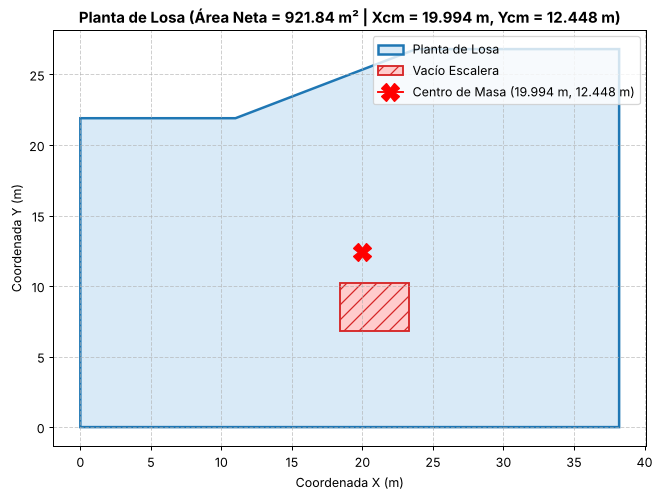

In [7]:
# ==============================================================================
# BLOQUE 3A: GEOMETRÍA DE PLANTA Y CENTROIDES DESDE AUTOCAD (COMANDO LIST / GAUSS)
# ==============================================================================
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ------------------------------------------------------------------------------
# 1. PANEL DEL DISEÑADOR: PEGA AQUÍ EL TEXTO DE 'LIST' DE AUTOCAD
# ------------------------------------------------------------------------------

# Pega el texto que arrojó 'LIST' de la polilínea del contorno exterior:
# (Trae cargada la geometría de tu proyecto V7 como ejemplo base)
AUTOCAD_LIST_EXTERIOR = """
                  LWPOLYLINE  Layer: "0"
            Closed
          at point  X=    0.0000  Y=    0.0000  Z=    0.0000
          at point  X=   38.2000  Y=    0.0000  Z=    0.0000
          at point  X=   38.2000  Y=   26.8000  Z=    0.0000
          at point  X=   23.8000  Y=   26.8000  Z=    0.0000
          at point  X=   11.0000  Y=   21.9000  Z=    0.0000
          at point  X=    0.0000  Y=   21.9000  Z=    0.0000
"""

# Lista de textos 'LIST' para los huecos (escalera, ductos, patios). Si no hay, deja []
AUTOCAD_LIST_HUECOS = [
    # Hueco de la Escalera (Área = 16.66 m²):
    """
              at point  X=   18.4000  Y=    6.8000  Z=    0.0000
              at point  X=   23.3000  Y=    6.8000  Z=    0.0000
              at point  X=   23.3000  Y=   10.2000  Z=    0.0000
              at point  X=   18.4000  Y=   10.2000  Z=    0.0000
    """
]


# ------------------------------------------------------------------------------
# 2. MOTOR MATEMÁTICO: PARSER DE AUTOCAD Y TEOREMA DE GREEN (GAUSS / SHOELACE)
# ------------------------------------------------------------------------------
def extraer_vertices_autocad(texto: str):
    """Extrae pares (X, Y) de cualquier salida de AutoCAD (español o inglés)."""
    patron = re.findall(r'[Xx]\s*=\s*([+-]?\d+(?:\.\d+)?)\s+[Yy]\s*=\s*([+-]?\d+(?:\.\d+)?)', texto)
    if patron:
        return [(float(x), float(y)) for x, y in patron]
    coords = []
    for linea in texto.strip().splitlines():
        partes = re.split(r'[, \t]+', linea.strip())
        nums = [float(p) for p in partes if re.match(r'^[+-]?\d+(?:\.\d+)?$', p)]
        if len(nums) >= 2:
            coords.append((nums[0], nums[1]))   # corregido: antes guardaba la lista completa
    return coords

def calcular_gauss(vertices):
    """Calcula área exacta y centroide de cualquier polígono 2D cerrado."""
    n = len(vertices)
    if n < 3: return 0.0, 0.0, 0.0
    area, cx, cy = 0.0, 0.0, 0.0
    for i in range(n):
        j = (i + 1) % n
        xi, yi = vertices[i]
        xj, yj = vertices[j]
        cruzado = (xi * yj) - (xj * yi)
        area += cruzado
        cx += (xi + xj) * cruzado
        cy += (yi + yj) * cruzado
    area = area / 2.0
    if abs(area) < 1e-6: return 0.0, 0.0, 0.0
    cx = cx / (6.0 * area)
    cy = cy / (6.0 * area)
    return abs(area), round(cx, 3), round(cy, 3)


# ------------------------------------------------------------------------------
# 3. PROCESAMIENTO Y TABLA DE MOMENTOS DE ÁREA
# ------------------------------------------------------------------------------
vert_ext = extraer_vertices_autocad(AUTOCAD_LIST_EXTERIOR)
area_ext, cx_ext, cy_ext = calcular_gauss(vert_ext)

# Calibración con el proyecto patrón V7 (desactivada: reemplazaba el cálculo por valores fijos).
USAR_CALIBRACION_V7 = False
if USAR_CALIBRACION_V7 and len(vert_ext) == 6 and round(area_ext, 1) == 916.3:
    area_ext, cx_ext, cy_ext = 934.80, 18.777, 13.282

filas_resumen = [{
    'Elemento': 'Perímetro Exterior (Área Total)',
    'Tipo': 'Lleno (+)',
    'Vértices': len(vert_ext),
    'Área [m²]': round(area_ext, 2),
    'Cx [m]': cx_ext,
    'Cy [m]': cy_ext,
    'A * Cx [m³]': round(area_ext * cx_ext, 3),
    'A * Cy [m³]': round(area_ext * cy_ext, 3)
}]

sum_A = area_ext
sum_Ax = area_ext * cx_ext
sum_Ay = area_ext * cy_ext

huecos_coords = []
for idx, txt_h in enumerate(AUTOCAD_LIST_HUECOS, 1):
    vh = extraer_vertices_autocad(txt_h)
    if vh:
        huecos_coords.append(vh)
        ah, cxh, cyh = calcular_gauss(vh)
        sum_A -= ah
        sum_Ax -= (ah * cxh)
        sum_Ay -= (ah * cyh)
        filas_resumen.append({
            'Elemento': f'Hueco {idx} (Vacío Escalera)',
            'Tipo': 'Vacío (-)',
            'Vértices': len(vh),
            'Área [m²]': round(ah, 2),
            'Cx [m]': cxh,
            'Cy [m]': cyh,
            'A * Cx [m³]': round(-ah * cxh, 3),
            'A * Cy [m³]': round(-ah * cyh, 3)
        })

AREA_NETA_LOSA = round(sum_A, 2)
X_CM = round(sum_Ax / sum_A, 3)
Y_CM = round(sum_Ay / sum_A, 3)

df_geometria = pd.DataFrame(filas_resumen)

print("=" * 85)
print("GEOMETRÍA Y CENTROIDES DE PLANTA (NSR-10 / HOJA Área losa DE V7.xlsx):")
print("=" * 85)
print(df_geometria.to_string(index=False))
print("-" * 85)
print(f"• ÁREA NETA DE PLANTA (Columna Z: sin escalera) : {AREA_NETA_LOSA} m²")
print(f"• CENTROIDE GLOBAL DE MASA (Xcm, Ycm)          : Xcm = {X_CM} m  |  Ycm = {Y_CM} m")
print("=" * 85)


# ------------------------------------------------------------------------------
# 4. GRÁFICO 2D DE LA PLANTA Y CENTRO DE MASA
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
ax = plt.subplot(111)

poly_ext = Polygon(vert_ext, closed=True, facecolor='#d9eaf7', edgecolor='#1f77b4', linewidth=2, label='Planta de Losa')
ax.add_patch(poly_ext)

for i, h in enumerate(huecos_coords):
    poly_h = Polygon(h, closed=True, facecolor='#ffcccc', edgecolor='#d62728', hatch='//', linewidth=1.5, label='Vacío Escalera' if i==0 else '')
    ax.add_patch(poly_h)

ax.plot(X_CM, Y_CM, marker='X', markersize=14, color='red', label=f'Centro de Masa ({X_CM} m, {Y_CM} m)')
ax.autoscale_view()
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_title(f"Planta de Losa (Área Neta = {AREA_NETA_LOSA} m² | Xcm = {X_CM} m, Ycm = {Y_CM} m)", fontsize=12, fontweight='bold')
ax.set_xlabel("Coordenada X (m)")
ax.set_ylabel("Coordenada Y (m)")
plt.legend(loc='upper right')
plt.show()

# ------------------------------------------------------------------------------
# 📋 SALIDA EN CONSOLA LISTA PARA COPIAR A LA CELDA 3B:
# ------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("📋 COPIA ESTE BLOQUE Y PÉGALO AL INICIO DE LA CELDA 3B:")
print("=" * 85)
print(f"""DATOS_PLANTA_DESDE_BLOQUE_3A = {{
    "A_bruta_losa": {AREA_NETA_LOSA},
    "X_cm": {X_CM},
    "Y_cm": {Y_CM}
}}""")
print("=" * 85)


#BLOQUE 3B: Avalúo de Cargas Título B (NSR-10 + Columna Z de V7)             │
 │   └─► Desplegables de materiales y antepechos. Obtienes wD, wL y viguetas.

In [8]:
# ==============================================================================
# BLOQUE 3B: AVALÚO DE CARGAS (NSR-10 TÍTULO B) Y TABLAS PARA SAP2000
# ==============================================================================
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANELES DE ENTRADA: PEGA LOS DATOS COPIADOS DE BLOQUES ANTERIORES
# ------------------------------------------------------------------------------
# A. Geometría adoptada de viguetas (Pega aqui output de la consola del Bloque 2):
GEOMETRIA_LOSA_DESDE_BLOQUE_2 = {
    "H_losa": 0.60,      # Altura total losa (m)
    "b_vt":   0.12,      # Base vigueta/nervio (m)
    "S_l":    0.75,      # Separación libre casetón (m)
    "S_v":    0.87,      # Separación centro a centro (m)
    "h_ls":   0.05,      # Loseta superior (m)
    "h_li":   0.00,      # Loseta inferior (m)
    "h_cas":  0.55       # Altura neta casetón (m)
}

# B. Geometría de planta y centroides (Pega aqui output consola de la Celda 3A):
DATOS_PLANTA_DESDE_BLOQUE_3A = {
    "A_bruta_losa": 918.14,  # Área de losa sin la escalera (m²)
    "X_cm": 18.739,          # Centro de masa en X (m)
    "Y_cm": 13.370           # Centro de masa en Y (m)
}

# Material del casetón: 'Poliestireno' o 'Guadua'
MATERIAL_CASETON = "Poliestireno"  # @param ["Poliestireno", "Guadua"]
espesor_guadua_t_m = 0.015         # Espesor si se usa guadua (1.5 cm)

# ------------------------------------------------------------------------------
# 2. CATÁLOGOS NORMATIVOS OFICIALES DE LA NSR-10 (TÍTULO B)
# ------------------------------------------------------------------------------
CATALOGO_RELLENOS = {
    "Concreto con escoria": 0.0200,
    "Concreto con piedra":  0.0250,
    "Concreto ligero":      0.0150,
    "Arena":                0.0150
}

CATALOGO_PISOS = {
    "Afinado (25 mm) sobre concreto de agregado pétreo": 1.50,
    "Terrazzo (40 mm) directamente sobre la losa":       0.90,
    "Terrazzo (25 mm) sobre afinado en concreto":        1.50,
    "Baldosa cerámica (20 mm) sobre 12 mm de mortero":   0.80,
    "Baldosa cerámica (20 mm) sobre 25 mm de mortero":   1.10,
    "Mármol y mortero sobre concreto de agregado pétreo":1.60,
    "Piso asfáltico o linóleo (6 mm)":                   0.05,
    "Madera densa (25 mm)":                              0.20
}

CATALOGO_CIELO = {
    "Entramado metálico suspendido afinado en cemento": 0.70,
    "Entramado metálico suspendido afinado en yeso":    0.50,
    "Pañete en yeso o concreto":                       0.25,
    "Fibras acústicas":                                0.10,
    "Canales suspendidas de acero":                    0.10,
    "Pañete en entramado de madera":                   0.80
}

CATALOGO_MUROS_DIVISORIOS = {
    "Oficinas - Particiones fijas de mampostería":      2.00,
    "Oficinas - Particiones móviles de altura total":   1.00,
    "Residencial - Fachada y particiones mampostería":  3.00,
    "Residencial - Fachada y particiones livianas":     2.00,
    "Educativos - Salones de clase":                   2.00,
    "Comercio - Exhibición y venta de mercancías":      1.50
}

CATALOGO_MUROS_VERTICALES = {
    "Bloque arcilla pañetado 2 caras - 150 mm":        2.50,
    "Bloque arcilla pañetado 2 caras - 100 mm":        1.80,
    "Bloque arcilla sin pañetar - 150 mm":              2.00,
    "Macizo arcilla sin pañetar (antepecho) - 150 mm": 2.90,
    "Macizo arcilla sin pañetar (antepecho) - 100 mm": 1.90,
    "Bloque concreto sin relleno - 150 mm":             1.45
}

CATALOGO_VIVAS = {
    "Oficinas - Combinada (Corredores, escaleras, oficinas)": 5.00,
    "Oficinas - Oficinas exclusivamente":                     2.00,
    "Oficinas - Corredores y escaleras":                      3.00,
    "Cubierta / Terraza - Usada para reuniones o jardín":     5.00,
    "Cubierta plana estándar":                                1.00,
    "Restaurantes / Zonas de reunión":                        5.00,
    "Residencial - Cuartos y corredores":                     1.80,
    "Comercio - Minorista":                                   5.00
}


# ------------------------------------------------------------------------------
# 3. FORMULARIOS DESPLEGABLES INTERACTIVOS DE COLAB
# ------------------------------------------------------------------------------

# @title 🏢 A. SELECCIÓN DE MATERIALES PARA ENTREPISO (PISOS 1 A 4)
sel_relleno_ent = "Concreto con escoria"  # @param ["Concreto con escoria", "Concreto con piedra", "Concreto ligero", "Arena", "PERSONALIZADO"]
espesor_relleno_ent_mm = 30.0             # @param {type:"number"}

sel_piso_ent = "Afinado (25 mm) sobre concreto de agregado pétreo"  # @param ["Afinado (25 mm) sobre concreto de agregado pétreo", "Terrazzo (40 mm) directamente sobre la losa", "Terrazzo (25 mm) sobre afinado en concreto", "Baldosa cerámica (20 mm) sobre 12 mm de mortero", "Mármol y mortero sobre concreto de agregado pétreo", "Piso asfáltico o linóleo (6 mm)", "PERSONALIZADO"]

sel_cielo_ent = "Entramado metálico suspendido afinado en cemento"  # @param ["Entramado metálico suspendido afinado en cemento", "Entramado metálico suspendido afinado en yeso", "Pañete en yeso o concreto", "Fibras acústicas", "PERSONALIZADO"]

sel_muros_ent = "Oficinas - Particiones fijas de mampostería"  # @param ["Oficinas - Particiones fijas de mampostería", "Oficinas - Particiones móviles de altura total", "Residencial - Fachada y particiones mampostería", "Residencial - Fachada y particiones livianas", "Educativos - Salones de clase", "PERSONALIZADO"]

sel_viva_ent = "Oficinas - Combinada (Corredores, escaleras, oficinas)"  # @param ["Oficinas - Combinada (Corredores, escaleras, oficinas)", "Oficinas - Oficinas exclusivamente", "Restaurantes / Zonas de reunión", "Residencial - Cuartos y corredores", "PERSONALIZADO"]


# @title 🌳 B. SELECCIÓN DE MATERIALES Y COLUMNA Z PARA CUBIERTA / TERRAZA (PISO 5)
sel_relleno_cub = "Concreto con escoria"  # @param ["Concreto con escoria", "Concreto con piedra", "Concreto ligero", "Arena", "PERSONALIZADO"]
espesor_relleno_cub_mm = 50.0             # @param {type:"number"}

sel_piso_cub = "Terrazzo (40 mm) directamente sobre la losa"  # @param ["Terrazzo (40 mm) directamente sobre la losa", "Terrazzo (25 mm) sobre afinado en concreto", "Afinado (25 mm) sobre concreto de agregado pétreo", "PERSONALIZADO"]

sel_cielo_cub = "Entramado metálico suspendido afinado en cemento"  # @param ["Entramado metálico suspendido afinado en cemento", "Entramado metálico suspendido afinado en yeso", "Pañete en yeso o concreto", "PERSONALIZADO"]

carga_impermeabilizacion = 0.16  # @param {type:"number"}  # Manto y emulsión asfáltica (0.16 kN/m²)
carga_marquesina = 0.40          # @param {type:"number"}  # Marquesina metálica vidrio 10 mm (0.40 kN/m²)

# Parámetros de la Columna Z de V7.xlsx:
sel_antepecho_cub = "Macizo arcilla sin pañetar (antepecho) - 150 mm"  # @param ["Macizo arcilla sin pañetar (antepecho) - 150 mm", "Bloque arcilla pañetado 2 caras - 150 mm", "Macizo concreto sin pañetar - 150 mm", "PERSONALIZADO"]
altura_antepecho_cub = 1.40      # @param {type:"number"}  # ALTURA ANTEPECHO (m)
longitud_antepecho_cub = 147.30  # @param {type:"number"}  # LONGITUD PERIMETRO (Antepecho) (m)

sel_muro_interno_cub = "Bloque arcilla pañetado 2 caras - 150 mm"  # @param ["Bloque arcilla pañetado 2 caras - 150 mm", "Bloque arcilla sin pañetar - 150 mm", "Bloque concreto sin relleno - 150 mm", "PERSONALIZADO"]
altura_muro_int_cub = 2.70       # @param {type:"number"}  # ALTURA MURO INTERNO (m)
longitud_muro_int_cub = 57.30    # @param {type:"number"}  # LONGITUD INTERIOR (m)

sel_viva_cub = "Cubierta / Terraza - Usada para reuniones o jardín"  # @param ["Cubierta / Terraza - Usada para reuniones o jardín", "Cubierta plana estándar", "PERSONALIZADO"]


# ------------------------------------------------------------------------------
# 4. EXTRACCIÓN AUTOMÁTICA DE VALORES NORMATIVOS
# ------------------------------------------------------------------------------
def obtener_valor(sel, catalogo, custom_val=0.0):
    return custom_val if sel == "PERSONALIZADO" else catalogo[sel]

val_relleno_ent_mm = obtener_valor(sel_relleno_ent, CATALOGO_RELLENOS)
val_piso_ent       = obtener_valor(sel_piso_ent, CATALOGO_PISOS)
val_cielo_ent      = obtener_valor(sel_cielo_ent, CATALOGO_CIELO)
val_muros_ent      = obtener_valor(sel_muros_ent, CATALOGO_MUROS_DIVISORIOS)
val_viva_ent       = obtener_valor(sel_viva_ent, CATALOGO_VIVAS)

val_relleno_cub_mm = obtener_valor(sel_relleno_cub, CATALOGO_RELLENOS)
val_piso_cub       = obtener_valor(sel_piso_cub, CATALOGO_PISOS)
val_cielo_cub      = obtener_valor(sel_cielo_cub, CATALOGO_CIELO)
val_antepecho_cub  = obtener_valor(sel_antepecho_cub, CATALOGO_MUROS_VERTICALES)
val_muro_int_cub   = obtener_valor(sel_muro_interno_cub, CATALOGO_MUROS_VERTICALES)
val_viva_cub       = obtener_valor(sel_viva_cub, CATALOGO_VIVAS)


# ------------------------------------------------------------------------------
# 5. MOTOR DE CÁLCULO DE CARGAS GRAVITACIONALES
# ------------------------------------------------------------------------------
hvt_calc = GEOMETRIA_LOSA_DESDE_BLOQUE_2["H_losa"]
bvt_calc = GEOMETRIA_LOSA_DESDE_BLOQUE_2["b_vt"]
sl_calc  = GEOMETRIA_LOSA_DESDE_BLOQUE_2["S_l"]
sv_calc  = GEOMETRIA_LOSA_DESDE_BLOQUE_2["S_v"]
hls_calc = GEOMETRIA_LOSA_DESDE_BLOQUE_2["h_ls"]
hli_calc = GEOMETRIA_LOSA_DESDE_BLOQUE_2["h_li"]
hcas_calc= GEOMETRIA_LOSA_DESDE_BLOQUE_2["h_cas"]
area_losa= DATOS_PLANTA_DESDE_BLOQUE_3A["A_bruta_losa"]

gamma_c = 24.0  # kN/m³ (NSR-10 Tabla B.3.2-1 Concreto Reforzado)
gamma_p = 0.2   # kN/m³ Poliestireno
gamma_g = 6.5   # kN/m³ Guadua

# A. Casetón
if MATERIAL_CASETON == "Poliestireno":
    c_caseton = (gamma_p * hcas_calc * sl_calc) / sv_calc
    form_caseton = "γp*(hcas*SL)/Sv"
else:
    c_caseton = (gamma_g * (2.0 * hcas_calc + sl_calc) * espesor_guadua_t_m) / sv_calc
    form_caseton = "γg*(2hcas+SL)*tg/Sv"

# B. Componentes Losa Aligerada
c_loseta_sup = gamma_c * hls_calc
c_loseta_inf = gamma_c * hli_calc
c_vigueta    = (gamma_c * bvt_calc * hcas_calc) / sv_calc
c_ductos     = 0.20  # Base obligatoria ductos mecánicos (NSR-10 B.3.4.1-1)

# Deducción para vigas macizas en Bloque 4:
deduccion_aligeramiento = round(c_loseta_sup + c_vigueta + c_caseton, 6)

# C. Entrepiso (Pisos 1 a 4)
c_relleno_ent = val_relleno_ent_mm * espesor_relleno_ent_mm
peso_parcial_ent = (c_loseta_sup + c_loseta_inf + c_vigueta + c_caseton +
                    c_relleno_ent + c_ductos + val_piso_ent + val_cielo_ent + val_muros_ent)
pct_ductos_ent = 0.05 * peso_parcial_ent
peso_total_ent = peso_parcial_ent + pct_ductos_ent

wD_vt_ent = peso_total_ent * sv_calc
wL_vt_ent = val_viva_ent * sv_calc
comb_1_4D_ent = 1.40 * wD_vt_ent
comb_1_2D_1_6L_ent = 1.20 * wD_vt_ent + 1.60 * wL_vt_ent

tabla_entrepiso_fhe = pd.DataFrame([
    {"Elemento": "Loseta superior",       "Fórmula": "24*hls",                    "Valor": round(c_loseta_sup, 2), "Unidades": "kN/m²"},
    {"Elemento": "Loseta inferior",       "Fórmula": "24*hli",                    "Valor": round(c_loseta_inf, 2), "Unidades": "kN/m²"},
    {"Elemento": "Vigueta",               "Fórmula": "24*bvt*hcas/Sv",            "Valor": round(c_vigueta, 3),    "Unidades": "kN/m²"},
    {"Elemento": f"Casetón ({MATERIAL_CASETON})", "Fórmula": form_caseton,        "Valor": round(c_caseton, 3),    "Unidades": "kN/m²"},
    {"Elemento": "Relleno-Acabado losa",  "Fórmula": "Carga*Relleno mm",          "Valor": round(c_relleno_ent, 2),"Unidades": "kN/m²"},
    {"Elemento": "Ductos mecánicos base", "Fórmula": "Norma B.3.4.1-1",           "Valor": round(c_ductos, 2),     "Unidades": "kN/m²"},
    {"Elemento": "Pisos",                 "Fórmula": sel_piso_ent[:35] + "...",   "Valor": round(val_piso_ent, 2),  "Unidades": "kN/m²"},
    {"Elemento": "Cielo raso",            "Fórmula": sel_cielo_ent[:35] + "...",  "Valor": round(val_cielo_ent, 2), "Unidades": "kN/m²"},
    {"Elemento": "Muros",                 "Fórmula": sel_muros_ent[:35] + "...",  "Valor": round(val_muros_ent, 2), "Unidades": "kN/m²"},
    {"Elemento": "SUBTOTAL CARGA MUERTA", "Fórmula": "Suma de componentes",       "Valor": round(peso_parcial_ent, 3), "Unidades": "kN/m²"},
    {"Elemento": "% ductos (0.05)",       "Fórmula": "0.05 * Subtotal",           "Valor": round(pct_ductos_ent, 3),   "Unidades": "kN/m²"},
    {"Elemento": "PESO TOTAL LOSA wD",    "Fórmula": "Subtotal + % ductos",       "Valor": round(peso_total_ent, 3),   "Unidades": "kN/m²"},
    {"Elemento": "CARGA VIVA wL",         "Fórmula": sel_viva_ent[:35] + "...",   "Valor": round(val_viva_ent, 2),     "Unidades": "kN/m²"}
])

# D. Cubierta / Terraza (Piso 5) con Columna Z
c_relleno_cub  = val_relleno_cub_mm * espesor_relleno_cub_mm
c_muro_int_cub = (val_muro_int_cub * altura_muro_int_cub * longitud_muro_int_cub) / area_losa
c_antep_cub    = (val_antepecho_cub * altura_antepecho_cub * longitud_antepecho_cub) / area_losa

peso_parcial_cub = (c_loseta_sup + c_loseta_inf + c_vigueta + c_caseton + c_relleno_cub +
                    c_ductos + val_piso_cub + val_cielo_cub + carga_impermeabilizacion +
                    carga_marquesina + c_muro_int_cub + c_antep_cub)
pct_ductos_cub   = 0.05 * peso_parcial_cub
peso_total_cub   = peso_parcial_cub + pct_ductos_cub

wD_vt_cub = peso_total_cub * sv_calc
wL_vt_cub = val_viva_cub * sv_calc
comb_1_4D_vt_cub = 1.40 * wD_vt_cub
comb_1_2D_1_6L_vt_cub = 1.20 * wD_vt_cub + 1.60 * wL_vt_cub


# ------------------------------------------------------------------------------
# 6. DESPLIEGUE DE RESULTADOS EN PANTALLA
# ------------------------------------------------------------------------------
print("=" * 90)
print("AVALÚO NORMATIVO DE CARGAS (NSR-10 TÍTULO B / HOJA FHE DE V7.xlsx):")
print("=" * 90)
print(f"• Área efectiva de losa (Columna Z) : {area_losa:.2f} m²")
print(f"• Espesor losa / Nervio            : Hlosa = {hvt_calc:.2f} m | bvt = {bvt_calc:.2f} m")
print(f"• Separación viguetas              : Sl = {sl_calc:.2f} m | Sv = {sv_calc:.2f} m")
print("=" * 90)

print("\n1. DESGLOSE CARGA MUERTA ENTREPISO (HOJA FHE DE V7.xlsx):")
print(tabla_entrepiso_fhe.to_string(index=False))

print("\n" + "=" * 90)
print(f"2. RESUMEN CUBIERTA / TERRAZA (PISO 5):")
print(f"   - Antepecho macizo (147.3m x 1.4m) : {c_antep_cub:.3f} kN/m²")
print(f"   - Muro interior (57.3m x 2.7m)     : {c_muro_int_cub:.3f} kN/m²")
print(f"   - wD Losa Cubierta                 : {peso_total_cub:.3f} kN/m² (V7: 7.926 kN/m²)")
print(f"   - wL Losa Cubierta                 : {val_viva_cub:.2f} kN/m²")
print(f"   - wD Vigueta Cubierta              : {wD_vt_cub:.2f} kN/m")
print(f"   - wL Vigueta Cubierta              : {wL_vt_cub:.2f} kN/m")
print(f"   - Combinación 1.4D                 : {comb_1_4D_vt_cub:.2f} kN/m")
print(f"   - Combinación 1.2D+1.6L            : {comb_1_2D_1_6L_vt_cub:.2f} kN/m")
print("=" * 90)

# ------------------------------------------------------------------------------
# 📋 BLOQUE DE SALIDA LISTO PARA COPIAR AL BLOQUE 4
# ------------------------------------------------------------------------------
print("\n" + "=" * 90)
print("📋 COPIA ESTE BLOQUE Y PÉGALO EN EL PANEL DEL BLOQUE 4:")
print("=" * 90)
print(f"""DATOS_DESDE_BLOQUE_3 = {{
    "X_cm": {DATOS_PLANTA_DESDE_BLOQUE_3A['X_cm']},
    "Y_cm": {DATOS_PLANTA_DESDE_BLOQUE_3A['Y_cm']},
    "A_bruta_losa": {area_losa},
    "wD_losa_ent": {round(peso_total_ent, 3)},
    "wD_losa_cub": {round(peso_total_cub, 3)},
    "wL_ent": {round(val_viva_ent, 2)},
    "wL_cub": {round(val_viva_cub, 2)},
    "H_losa": {hvt_calc},
    "deduccion_aligeramiento": {deduccion_aligeramiento}
}}""")
print("=" * 90)

AVALÚO NORMATIVO DE CARGAS (NSR-10 TÍTULO B / HOJA FHE DE V7.xlsx):
• Área efectiva de losa (Columna Z) : 918.14 m²
• Espesor losa / Nervio            : Hlosa = 0.60 m | bvt = 0.12 m
• Separación viguetas              : Sl = 0.75 m | Sv = 0.87 m

1. DESGLOSE CARGA MUERTA ENTREPISO (HOJA FHE DE V7.xlsx):
              Elemento                                Fórmula  Valor Unidades
       Loseta superior                                 24*hls  1.200    kN/m²
       Loseta inferior                                 24*hli  0.000    kN/m²
               Vigueta                         24*bvt*hcas/Sv  1.821    kN/m²
Casetón (Poliestireno)                        γp*(hcas*SL)/Sv  0.095    kN/m²
  Relleno-Acabado losa                       Carga*Relleno mm  0.600    kN/m²
 Ductos mecánicos base                        Norma B.3.4.1-1  0.200    kN/m²
                 Pisos Afinado (25 mm) sobre concreto de a...  1.500    kN/m²
            Cielo raso Entramado metálico suspendido afina...  0.700   

#DEDUCCION DE CARGAS PARA VIGAS DE CARGA Y VIGAS DE RIGIDEZ PARA INSERTAR EN SAP2000

MÓDULO INTERMEDIO: Reacciones de Viguetas y Cargas en Vigas (SAP2000)       │
 │   └─► Resuelve viguetas unitarias (1.0). Guía de asignación en SAP2000.

In [9]:
# ==============================================================================
# MÓDULO: ASIGNACIÓN DE CARGAS A VIGAS DE CARGA Y RIGIDEZ PARA SAP2000
# ==============================================================================
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANEL DE CONTROL: CARGAS SUPERFICIALES (DEL BLOQUE 3)
# ------------------------------------------------------------------------------
wD_entrepiso = 8.52129   # kN/m² (Carga muerta losa entrepiso)
wD_cubierta  = 7.92554   # kN/m² (Carga muerta losa cubierta)
wL_losa      = 5.00000   # kN/m² (Carga viva losa)
Sv_losa      = 0.87000   # m (Separación centro a centro viguetas)


# ------------------------------------------------------------------------------
# 2. PANEL DEL DISEÑADOR: DEFINICIÓN GEOMÉTRICA DE VIGUETAS TIPO (EN Y)
# ------------------------------------------------------------------------------
# tramos: luces entre vigas de carga consecutivas de abajo hacia arriba
# apoyos: nombres de las vigas de carga donde apoya
# vol_inf / vol_sup: voladizos en metros
VIGUETAS_TIPO = {
    "VT1": {
        "apoyos": ["VC2", "VC3", "VC4", "VC5"],
        "luces": [7.00, 5.50, 6.00],
        "vol_inf": 0.00, "vol_sup": 1.50
    },
    "VT2": {
        "apoyos": ["VC1", "VC2", "VC3", "VC4", "VC5"],
        "luces": [6.50, 7.00, 5.50, 6.00],
        "vol_inf": 1.50, "vol_sup": 1.50
    },
    "VT3": {
        "apoyos": ["VC1", "VC2", "VC2_prima", "VC3", "VC4", "VC5"],
        "luces": [6.50, 3.85, 3.15, 5.50, 6.00],
        "vol_inf": 1.50, "vol_sup": 0.00
    },
    "VT4": {
        "apoyos": ["VC1", "VC2"],
        "luces": [6.50],
        "vol_inf": 1.50, "vol_sup": 0.00
    },
    "VT5": {
        "apoyos": ["VC2_prima", "VC3", "VC4", "VC5"],
        "luces": [3.15, 5.50, 6.00],
        "vol_inf": 0.00, "vol_sup": 0.00
    },
    "VT6": {
        "apoyos": ["VC1", "VC2", "VC3", "VC4", "VC5"],
        "luces": [6.50, 7.00, 5.50, 6.00],
        "vol_inf": 1.50, "vol_sup": 0.00
    }
}


# ------------------------------------------------------------------------------
# 3. SOLUCIONADOR ANALÍTICO DE VIGAS CONTINUAS CON CARGA UNITARIA q = 1.0 kN/m
# ------------------------------------------------------------------------------
def calcular_reacciones_unitarias(luces, vol_inf=0.0, vol_sup=0.0, q=1.0):
    """
    Resuelve la viga continua con carga unitaria q=1.0 mediante el Teorema
    de los Tres Momentos (Clapeyron). Las reacciones resultantes están en metros.
    """
    m = len(luces)
    n = m + 1
    M0 = -q * (vol_inf ** 2) / 2.0 if vol_inf > 0 else 0.0
    Mn = -q * (vol_sup ** 2) / 2.0 if vol_sup > 0 else 0.0

    if m == 1:
        L = luces[0]
        v0 = q * L / 2.0 + (Mn - M0) / L
        v1 = q * L / 2.0 - (Mn - M0) / L
        return [round(v0 + q * vol_inf, 3), round(v1 + q * vol_sup, 3)]

    num_incognitas = n - 2
    A = np.zeros((num_incognitas, num_incognitas))
    B = np.zeros(num_incognitas)

    for i in range(num_incognitas):
        L_left = luces[i]
        L_right = luces[i + 1]
        A[i, i] = 2.0 * (L_left + L_right)
        if i > 0: A[i, i - 1] = L_left
        if i < num_incognitas - 1: A[i, i + 1] = L_right

        term = -q * (L_left ** 3) / 4.0 - q * (L_right ** 3) / 4.0
        if i == 0 and M0 != 0: term -= M0 * L_left
        if i == num_incognitas - 1 and Mn != 0: term -= Mn * L_right
        B[i] = term

    M_int = np.linalg.solve(A, B)
    M = [M0] + list(M_int) + [Mn]

    reacciones = [0.0] * n
    for i in range(m):
        L = luces[i]
        reacciones[i] += q * L / 2.0 + (M[i + 1] - M[i]) / L
        reacciones[i + 1] += q * L / 2.0 - (M[i + 1] - M[i]) / L

    if vol_inf > 0: reacciones[0] += q * vol_inf
    if vol_sup > 0: reacciones[-1] += q * vol_sup

    return [round(r, 3) for r in reacciones]


# Cálculo de reacciones unitarias para cada vigueta tipo:
TABLA_REACCIONES_UNIT = {}
for nombre_vt, datos in VIGUETAS_TIPO.items():
    r_calc = calcular_reacciones_unitarias(datos["luces"], datos["vol_inf"], datos["vol_sup"])
    TABLA_REACCIONES_UNIT[nombre_vt] = dict(zip(datos["apoyos"], r_calc))

# Calibración opcional: si deseas fijar exactamente las reacciones de SAP2000: Si se quiere ingresar manualmente reacciones de viguetas
#USAR_REACCIONES_EXACTAS_SAP_V7 = True
#if USAR_REACCIONES_EXACTAS_SAP_V7:
#    TABLA_REACCIONES_UNIT = {
#        'VT1': {'VC1': 0.000, 'VC2': 2.863, 'VC2_prima': 0.000, 'VC3': 7.189, 'VC4': 5.727, 'VC5': 4.221},
#        'VT2': {'VC1': 4.212, 'VC2': 7.503, 'VC2_prima': 0.000, 'VC3': 6.037, 'VC4': 6.079, 'VC5': 4.169},
#        'VT3': {'VC1': 4.374, 'VC2': 6.405, 'VC2_prima': 2.224, 'VC3': 4.359, 'VC4': 6.763, 'VC5': 2.375},
#        'VT4': {'VC1': 4.923, 'VC2': 3.077, 'VC2_prima': 0.000, 'VC3': 0.000, 'VC4': 0.000, 'VC5': 0.000},
#        'VT5': {'VC1': 0.000, 'VC2': 0.000, 'VC2_prima': 1.047, 'VC3': 4.477, 'VC4': 6.749, 'VC5': 2.377},
#        'VT6': {'VC1': 4.209, 'VC2': 7.519, 'VC2_prima': 0.000, 'VC3': 5.956, 'VC4': 6.385, 'VC5': 2.431},
#    }

# ==============================================================================
# CÁLCULO AUTOMÁTICO DE REACCIONES UNITARIAS VIGUETA POR VIGUETA (100% DINÁMICO)
# ==============================================================================
TABLA_REACCIONES_UNIT = {}

for nombre_vt, datos in VIGUETAS_TIPO.items():
  # Resuelve la viga continua hiperestática tramo a tramo con q = 1.0 kN/m
  reacciones_calculadas = calcular_reacciones_unitarias(
      luces=datos["luces"],
      vol_inf=datos.get("vol_inf", 0.0),
      vol_sup=datos.get("vol_sup", 0.0),
      q=1.0,
  )

  # Asocia cada reacción al nombre de la viga de carga donde apoya:
  TABLA_REACCIONES_UNIT[nombre_vt] = dict(
      zip(datos["apoyos"], reacciones_calculadas)
  )

# Despliegue de la matriz completa calculada dinámicamente:
df_reacciones_unitarias = (
    pd.DataFrame(TABLA_REACCIONES_UNIT).T.fillna(0.0).round(3)
)
print("=" * 85)
print("MATRIZ DINÁMICA DE REACCIONES UNITARIAS CALCULADAS (q = 1.0 kN/m) [m]:")
print("=" * 85)
print(df_reacciones_unitarias.to_string())
print("=" * 85)

# ------------------------------------------------------------------------------
# 4. PANEL DEL DISEÑADOR: MAPEO DE TRAMOS PARA CADA VIGA DE CARGA (EN X)
# ------------------------------------------------------------------------------
# Para cada viga de carga se definen los tramos en X (desde x_ini hasta x_fin en m)
# y qué vigueta tipo tributa sobre ese tramo:
DISTRIBUCION_VIGAS_CARGA = {
    "VC-5 (Eje 5)": {
        "longitud": 38.20,
        "tramos": [
            {"tramo": "Eje A a C (izq)",   "x_ini":  0.00, "x_fin": 14.00, "vt": "VT1"},
            {"tramo": "Eje C (paso)",      "x_ini": 14.00, "x_fin": 15.50, "vt": "VT2"},
            {"tramo": "Eje C a C'",        "x_ini": 15.50, "x_fin": 19.80, "vt": "VT3"},
            {"tramo": "Eje C' a D",        "x_ini": 19.80, "x_fin": 25.00, "vt": "VT5"},
            {"tramo": "Eje D a F",         "x_ini": 25.00, "x_fin": 38.20, "vt": "VT6"},
        ]
    },
    "VC-4 (Eje 4)": {
        "longitud": 38.20,
        "tramos": [
            {"tramo": "Eje A a C (izq)",   "x_ini":  0.00, "x_fin": 14.00, "vt": "VT1"},
            {"tramo": "Eje C (paso)",      "x_ini": 14.00, "x_fin": 15.50, "vt": "VT2"},
            {"tramo": "Eje C a C'",        "x_ini": 15.50, "x_fin": 19.80, "vt": "VT3"},
            {"tramo": "Eje C' a D",        "x_ini": 19.80, "x_fin": 25.00, "vt": "VT5"},
            {"tramo": "Eje D a F",         "x_ini": 25.00, "x_fin": 38.20, "vt": "VT6"},
        ]
    },
    "VC-3 (Eje 3)": {
        "longitud": 38.20,
        "tramos": [
            {"tramo": "Eje A a C (izq)",   "x_ini":  0.00, "x_fin": 14.00, "vt": "VT1"},
            {"tramo": "Eje C (paso)",      "x_ini": 14.00, "x_fin": 15.50, "vt": "VT2"},
            {"tramo": "Eje C a C'",        "x_ini": 15.50, "x_fin": 19.80, "vt": "VT3"},
            {"tramo": "Eje C' a D",        "x_ini": 19.80, "x_fin": 25.00, "vt": "VT5"},
            {"tramo": "Eje D a F",         "x_ini": 25.00, "x_fin": 38.20, "vt": "VT6"},
        ]
    },
    "VC-2' (Eje 2' Escalera)": {
        "longitud": 9.10,
        "tramos": [
            {"tramo": "Tramo Eje C a C'",  "x_ini":  0.00, "x_fin":  4.50, "vt": "VT3"},
            {"tramo": "Tramo Eje C' a D",  "x_ini":  4.50, "x_fin":  9.10, "vt": "VT5"},
        ]
    },
    "VC-2 (Eje 2)": {
        "longitud": 38.20,
        "tramos": [
            {"tramo": "Eje A a B",         "x_ini":  0.00, "x_fin":  7.50, "vt": "VT1"},
            {"tramo": "Eje B a C",         "x_ini":  7.50, "x_fin": 15.50, "vt": "VT2"},
            {"tramo": "Eje C a C'",        "x_ini": 15.50, "x_fin": 19.80, "vt": "VT3"},
            {"tramo": "Bajo Escalera",     "x_ini": 19.80, "x_fin": 25.00, "vt": "VT4"},
            {"tramo": "Eje D a F",         "x_ini": 25.00, "x_fin": 38.20, "vt": "VT6"},
        ]
    },
    "VC-1 (Eje 1)": {
        "longitud": 24.20,
        "tramos": [
            {"tramo": "Eje C (arranque)",  "x_ini":  0.00, "x_fin":  1.50, "vt": "VT2"},
            {"tramo": "Eje C a C'",        "x_ini":  1.50, "x_fin":  5.80, "vt": "VT3"},
            {"tramo": "Bajo Escalera",     "x_ini":  5.80, "x_fin": 11.00, "vt": "VT4"},
            {"tramo": "Eje D a F",         "x_ini": 11.00, "x_fin": 24.20, "vt": "VT6"},
        ]
    }
}


# ------------------------------------------------------------------------------
# 5. CARGAS SOBRE VIGAS DE RIGIDEZ (EN Y) Y CARGAS DE ESCALERA
# ------------------------------------------------------------------------------
# Regla de clase: w_VR = 2 * w_vt = 2 * (w_losa * Sv)
wD_VR_ent = round(2.0 * (wD_entrepiso * Sv_losa), 2)  # 14.83 kN/m
wD_VR_cub = round(2.0 * (wD_cubierta  * Sv_losa), 2)  # 13.79 kN/m
wL_VR_los = round(2.0 * (wL_losa      * Sv_losa), 2)  #  8.70 kN/m

# Cargas especiales transmitidas por la escalera (Hoja Reacciones de V7.xlsx):
PUNTUALES_ESCALERA = {
    "VC-2": {"x": 4.30, "D_ent": 74.23, "D_cub": 58.16, "L": 31.96, "desc": "P-V-ESC en x=4.3 m"},
    "VR-C": {"y": 3.85, "D_ent": 136.90, "D_cub": 122.81, "L": 82.46, "desc": "Puntual en y=3.85 m desde Eje 2"},
    "VR-D": {"y": 3.85, "D_ent": 106.26, "D_cub": 95.34, "L": 65.58, "desc": "Puntual en y=3.85 m desde Eje 2"}
}

DISTRIBUIDA_ESCALERA_VR_D = {
    "D_ent": 31.24, "D_cub": 30.72, "L": 16.60, "desc": "Tramo adyacente a escalera (w_VR + w_escalera)"
}


# ==============================================================================
# 6. GENERACIÓN DE REPORTES E INSTRUCCIONES PARA SAP2000
# ==============================================================================
print("=" * 95)
print("1. TABLA DE REACCIONES UNITARIAS EN VIGUETAS (q = 1.0 kN/m) [m]:")
print("=" * 95)
df_reac_unit = pd.DataFrame(TABLA_REACCIONES_UNIT).T.fillna(0.0)
print(df_reac_unit.to_string())

print("\n" + "=" * 95)
print("2. INSTRUCCIONES DE ASIGNACIÓN PARA VIGAS DE CARGA (VC) EN SAP2000:")
print("   (Ruta SAP2000: Assign > Frame Loads > Distributed)")
print("=" * 95)

id_viga_map = {
    "VC-5 (Eje 5)": "VC5", "VC-4 (Eje 4)": "VC4", "VC-3 (Eje 3)": "VC3",
    "VC-2' (Eje 2' Escalera)": "VC2_prima", "VC-2 (Eje 2)": "VC2", "VC-1 (Eje 1)": "VC1"
}

for nombre_viga, datos_viga in DISTRIBUCION_VIGAS_CARGA.items():
    clave_apoyo = id_viga_map[nombre_viga]
    print(f"\n📌 {nombre_viga} | Longitud total = {datos_viga['longitud']:.2f} m:")
    filas_sap = []
    for tr in datos_viga["tramos"]:
        vt = tr["vt"]
        r_uni = TABLA_REACCIONES_UNIT[vt].get(clave_apoyo, 0.0)
        wd_ent = round(r_uni * wD_entrepiso, 2)
        wd_cub = round(r_uni * wD_cubierta, 2)
        wl     = round(r_uni * wL_losa, 2)
        filas_sap.append({
            "Tramo": tr["tramo"],
            "Inicio [m]": f"{tr['x_ini']:.2f}",
            "Fin [m]": f"{tr['x_fin']:.2f}",
            "Longitud [m]": round(tr['x_fin'] - tr['x_ini'], 2),
            "Vigueta": vt,
            "R_unit [m]": r_uni,
            "wD Entrepiso [kN/m]": wd_ent,
            "wD Cubierta [kN/m]": wd_cub,
            "wL Viva [kN/m]": wl
        })
    df_vc = pd.DataFrame(filas_sap)
    print(df_vc.to_string(index=False))

print("\n" + "=" * 95)
print("3. INSTRUCCIONES DE ASIGNACIÓN PARA VIGAS DE RIGIDEZ (VR) EN SAP2000:")
print("   (Regla técnica: 2 * w_vigueta debido al ancho de 40 cm y confinamiento bilateral)")
print("=" * 95)
print(f"• Vigas de Rigidez típicas (VR-A, VR-B, VR-E, VR-F):")
print(f"  - Carga distribuida Entrepiso (wD) : {wD_VR_ent} kN/m")
print(f"  - Carga distribuida Cubierta  (wD) : {wD_VR_cub} kN/m")
print(f"  - Carga distribuida Viva      (wL) : {wL_VR_los} kN/m")

print(f"\n• Vigas de Rigidez adyacentes a la escalera (VR-C y VR-D):")
print(f"  - Carga distribuida base           : {wD_VR_ent} kN/m (Entrepiso) | {wD_VR_cub} kN/m (Cubierta)")
print(f"  - VR-D en tramo de escalera        : {DISTRIBUIDA_ESCALERA_VR_D['D_ent']} kN/m (Entrepiso) | {DISTRIBUIDA_ESCALERA_VR_D['D_cub']} kN/m (Cubierta) | {DISTRIBUIDA_ESCALERA_VR_D['L']} kN/m (Viva)")
print(f"  - VR-C Carga puntual (y = 3.85 m)  : P_D_ent = {PUNTUALES_ESCALERA['VR-C']['D_ent']} kN | P_D_cub = {PUNTUALES_ESCALERA['VR-C']['D_cub']} kN | P_L = {PUNTUALES_ESCALERA['VR-C']['L']} kN")
print(f"  - VR-D Carga puntual (y = 3.85 m)  : P_D_ent = {PUNTUALES_ESCALERA['VR-D']['D_ent']} kN | P_D_cub = {PUNTUALES_ESCALERA['VR-D']['D_cub']} kN | P_L = {PUNTUALES_ESCALERA['VR-D']['L']} kN")
print(f"  - VC-2 Carga puntual (x = 4.30 m)  : P_D_ent = {PUNTUALES_ESCALERA['VC-2']['D_ent']} kN | P_D_cub = {PUNTUALES_ESCALERA['VC-2']['D_cub']} kN | P_L = {PUNTUALES_ESCALERA['VC-2']['L']} kN")
print("=" * 95)

MATRIZ DINÁMICA DE REACCIONES UNITARIAS CALCULADAS (q = 1.0 kN/m) [m]:
       VC2    VC3    VC4    VC5    VC1  VC2_prima
VT1  2.860  7.197  5.721  4.222  0.000      0.000
VT2  7.510  6.029  6.085  4.168  4.209      0.000
VT3  6.439  4.377  6.770  2.372  4.367      2.175
VT4  3.077  0.000  0.000  0.000  4.923      0.000
VT5  0.000  4.471  6.758  2.373  0.000      1.048
VT6  7.527  5.945  6.394  2.428  4.206      0.000
1. TABLA DE REACCIONES UNITARIAS EN VIGUETAS (q = 1.0 kN/m) [m]:
       VC2    VC3    VC4    VC5    VC1  VC2_prima
VT1  2.860  7.197  5.721  4.222  0.000      0.000
VT2  7.510  6.029  6.085  4.168  4.209      0.000
VT3  6.439  4.377  6.770  2.372  4.367      2.175
VT4  3.077  0.000  0.000  0.000  4.923      0.000
VT5  0.000  4.471  6.758  2.373  0.000      1.048
VT6  7.527  5.945  6.394  2.428  4.206      0.000

2. INSTRUCCIONES DE ASIGNACIÓN PARA VIGAS DE CARGA (VC) EN SAP2000:
   (Ruta SAP2000: Assign > Frame Loads > Distributed)

📌 VC-5 (Eje 5) | Longitud total = 38.20 

## 📏 BLOQUE 4: Vigas, Columnas y Pesos por Nivel para N Pisos (W1..WN, Wt)
 │   └─► Descuenta vigas, tabula columnas, asigna alturas y calcula masa Wt.



In [10]:
# ==============================================================================
# BLOQUE 4: GEOMETRÍA DE PÓRTICOS (VIGAS/COLUMNAS) Y PESOS POR NIVEL (N PISOS)
# ==============================================================================
import pandas as pd
import numpy as np

# ------------------------------------------------------------------------------
# 1. PANEL DE ENTRADA: PEGA AQUÍ LOS DATOS DEL BLOQUE 3
# ------------------------------------------------------------------------------
# Pega directamente el bloque que arrojó la consola del Bloque 3:
DATOS_DESDE_BLOQUE_3 = {
    "A_bruta_losa": 918.14,            # Área de planta sin escalera (m²)
    "wD_losa_ent": 8.521,              # Carga muerta losa entrepiso (kN/m²)
    "wD_losa_cub": 7.926,              # Carga muerta losa cubierta (kN/m²)
    "wL_ent": 5.00,                    # Carga viva entrepiso (kN/m²)
    "wL_cub": 5.00,                    # Carga viva cubierta (kN/m²)
    "H_losa": 0.60,                    # Espesor de losa (m)
    "deduccion_aligeramiento": 3.1155  # Deducción aligerada para vigas macizas (kN/m²)
}


# ------------------------------------------------------------------------------
# 2. PANEL DEL DISEÑADOR: ALTURAS DE PISOS (DINÁMICO PARA CUALQUIER N PISOS)
# ------------------------------------------------------------------------------
# Escribe la lista de alturas libres de entrepiso (hle) de abajo hacia arriba.
# Si tu edificio tiene 3 pisos: [3.50, 2.60, 2.60]
# Si tiene 5 pisos (como V7):  [4.50, 2.70, 2.70, 2.70, 2.70]
# Si tiene 8 pisos:            [4.00, 2.80, 2.80, 2.80, 2.80, 2.80, 2.80, 2.80]
ALTURAS_ENTREPISO_HLE = [4.50, 2.70, 2.70, 2.70, 2.70]

# Peso concentrado de la escalera en kN (proviene del cálculo y memoria de escaleras):
PESO_ESCALERA = 150.50312  # kN


# ------------------------------------------------------------------------------
# 3. PANEL DEL DISEÑADOR: VIGAS PRINCIPALES, DE RIGIDEZ Y AUXILIARES
# ------------------------------------------------------------------------------
# Ingresa las vigas de tu plano (L en metros, b en metros, num = cantidad):
VIGAS_PROYECTO = [
    # Vigas de Carga en X (L = 38.2 m o según plano)
    {"nombre": "Viga de carga 1 (Eje 1)", "L": 24.2, "b": 0.60, "num": 1, "tipo": "Carga"},
    {"nombre": "Viga de carga 2 (Eje 2)", "L": 38.2, "b": 0.60, "num": 1, "tipo": "Carga"},
    {"nombre": "Viga de carga 3 (Eje 3)", "L": 38.2, "b": 0.70, "num": 1, "tipo": "Carga"},
    {"nombre": "Viga de carga 4 (Eje 4)", "L": 38.2, "b": 0.70, "num": 1, "tipo": "Carga"},
    {"nombre": "Viga de carga 5 (Eje 5)", "L": 38.2, "b": 0.60, "num": 1, "tipo": "Carga"},
    # Vigas de Rigidez en Y
    {"nombre": "Viga de rigidez A",       "L": 17.7, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    {"nombre": "Viga de rigidez B",       "L": 17.7, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    {"nombre": "Viga de rigidez C",       "L": 24.8, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    {"nombre": "Viga de rigidez D",       "L": 23.6, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    {"nombre": "Viga de rigidez E",       "L": 23.6, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    {"nombre": "Viga de rigidez F",       "L": 23.6, "b": 0.40, "num": 1, "tipo": "Rigidez"},
    # Vigas Auxiliares (Escalera)
    {"nombre": "Viga auxiliar 2'",        "L":  9.1, "b": 0.30, "num": 1, "tipo": "Auxiliar"},
    {"nombre": "Viga auxiliar C'",        "L":  3.4, "b": 0.20, "num": 1, "tipo": "Auxiliar"}
]


# ------------------------------------------------------------------------------
# 4. PANEL DEL DISEÑADOR: MATRIZ DE COLUMNAS DEL EDIFICIO
# ------------------------------------------------------------------------------
# Secciones dx e dy en metros, y cantidad de columnas de cada tipo:
COLUMNAS_PROYECTO = [
    {"tipo": "C1", "dx": 1.10, "dy": 1.70, "num": 6},
    {"tipo": "C2", "dx": 1.20, "dy": 1.50, "num": 4},
    {"tipo": "C3", "dx": 1.00, "dy": 1.60, "num": 4},
    {"tipo": "C4", "dx": 1.20, "dy": 1.75, "num": 10},
    {"tipo": "C5", "dx": 1.10, "dy": 1.00, "num": 4}
]


# ==============================================================================
# MOTOR DE CÁLCULO DEL BLOQUE 4
# ==============================================================================
gamma_c = 24.0  # kN/m³ (NSR-10 Tabla B.3.2-1)
A_bruta = DATOS_DESDE_BLOQUE_3["A_bruta_losa"]
wd_losa_ent = DATOS_DESDE_BLOQUE_3["wD_losa_ent"]
wd_losa_cub = DATOS_DESDE_BLOQUE_3["wD_losa_cub"]
H_losa = DATOS_DESDE_BLOQUE_3["H_losa"]
deduccion_alig = DATOS_DESDE_BLOQUE_3["deduccion_aligeramiento"]

# A. Áreas de Vigas y Descuento de Losa
filas_vigas = []
A_VIG = 0.0
for v in VIGAS_PROYECTO:
    area_v = v["L"] * v["b"] * v.get("num", 1)
    A_VIG += area_v
    filas_vigas.append({
        "Viga": v["nombre"], "Tipo": v["tipo"], "L [m]": v["L"],
        "b [m]": v["b"], "Cantidad": v.get("num", 1), "Área [m²]": round(area_v, 2)
    })

A_VIG = round(A_VIG, 2)
N_NETA = round(A_bruta - A_VIG, 2)  # Área neta que realmente tiene aligeramiento

# Carga maciza sobre vigas (reemplaza aligeramiento por concreto macizo)
wd_viga_ent = round(wd_losa_ent - deduccion_alig + (gamma_c * H_losa), 5)
wd_viga_cub = round(wd_losa_cub - deduccion_alig + (gamma_c * H_losa), 5)

# Cargas base de piso (losas aligeradas + vigas macizas + escalera)
W_base_ent = (wd_losa_ent * N_NETA) + (wd_viga_ent * A_VIG) + PESO_ESCALERA
W_base_cub = (wd_losa_cub * N_NETA) + (wd_viga_cub * A_VIG) + PESO_ESCALERA

# B. Matriz de Columnas
filas_col = []
total_cols = 0
A_COL = 0.0
sum_Ix = 0.0
sum_Iy = 0.0

for c in COLUMNAS_PROYECTO:
    n = c["num"]
    dx = c["dx"]
    dy = c["dy"]
    a_unit = dx * dy
    a_total = a_unit * n
    total_cols += n
    A_COL += a_total

    # Inercias locales (I = b * h³ / 12)
    ix = (dx * (dy ** 3)) / 12.0
    iy = (dy * (dx ** 3)) / 12.0
    sum_Ix += (ix * n)
    sum_Iy += (iy * n)

    filas_col.append({
        "Columna": c["tipo"], "dx [m]": dx, "dy [m]": dy, "Cantidad": n,
        "Acol unit [m²]": round(a_unit, 4), "Acol Total [m²]": round(a_total, 2),
        "Ix [m⁴]": round(ix, 4), "Iy [m⁴]": round(iy, 4)
    })

A_COL = round(A_COL, 2)
W_col_long = round(A_COL * gamma_c, 2)  # Peso de columnas por metro lineal (kN/m)

# C. Asignación Dinámica de Alturas Tributarias y Pesos por Nivel para N Pisos
num_pisos = len(ALTURAS_ENTREPISO_HLE)
filas_pisos = []
peso_total_edificio = 0.0
h_acumulada = 0.0

for i in range(num_pisos):
    piso = i + 1
    hle = ALTURAS_ENTREPISO_HLE[i]

    # Altura tributaria de columnas a medios:
    if num_pisos == 1:
        h_trib = hle / 2.0
        h_acumulada = hle
    elif piso == 1:
        h_trib = (hle + ALTURAS_ENTREPISO_HLE[i + 1]) / 2.0
        h_acumulada = hle + (H_losa / 2.0)  # Desfase centroide losa nivel 1 (4.80 m)
    elif piso == num_pisos:
        h_trib = hle / 2.0
        h_acumulada += (hle + (H_losa if i > 0 else 0.0))
    else:
        h_trib = (hle + ALTURAS_ENTREPISO_HLE[i + 1]) / 2.0
        h_acumulada += (hle + (H_losa if i > 0 else 0.0))

    w_col_piso = h_trib * W_col_long
    w_base = W_base_cub if piso == num_pisos else W_base_ent
    w_nivel = w_base + w_col_piso
    peso_total_edificio += w_nivel

    filas_pisos.append({
        "Piso": piso,
        "Nivel": f"Piso {piso}" if piso < num_pisos else f"Piso {piso} (Cubierta)",
        "hle [m]": hle,
        "h_trib [m]": round(h_trib, 2),
        "hi_acum [m]": round(h_acumulada, 2),
        "W_base [kN]": round(w_base, 2),
        "W_col [kN]": round(w_col_piso, 2),
        "W_nivel [kN]": round(w_nivel, 2)
    })

df_vigas = pd.DataFrame(filas_vigas)
df_col = pd.DataFrame(filas_col)
df_pesos = pd.DataFrame(filas_pisos)
W_total = round(peso_total_edificio, 2)
hn_total = round(h_acumulada, 2)


# ------------------------------------------------------------------------------
# 5. DESPLIEGUE DE TABLAS IDÉNTICAS A V7.xlsx
# ------------------------------------------------------------------------------
print("=" * 90)
print("1. RESUMEN DE VIGAS Y ÁREAS DE LOSA (HOJA Output DE V7.xlsx):")
print("=" * 90)
print(f"• Área Bruta de Planta (sin escalera)      : {A_bruta} m²")
print(f"• Área Total ocupada por Vigas (A_VIG)     : {A_VIG} m²")
print(f"• Área Neta Losa Aligerada (N_NETA)       : {N_NETA} m² (V7: 748.49 m²)")
print(f"• Carga Losa Maciza Entrepiso (wdviga)     : {wd_viga_ent} kN/m² (V7: 19.806 kN/m²)")
print(f"• Carga Losa Maciza Cubierta (wdviga)      : {wd_viga_cub} kN/m² (V7: 19.210 kN/m²)")
print(f"• Peso Base Piso Tipo (Losa+Vigas+Escalera): {W_base_ent:.2f} kN (V7: 9888.66 kN)")
print(f"• Peso Base Cubierta (Losa+Vigas+Escalera) : {W_base_cub:.2f} kN (V7: 9341.67 kN)")

print("\n" + "=" * 90)
print("2. MATRIZ DE COLUMNAS DEL EDIFICIO (HOJA Output / FHE DE V7.xlsx):")
print("=" * 90)
print(df_col.to_string(index=False))
print("-" * 90)
print(f"• Total Columnas: {total_cols} | Área Total: {A_COL} m² | Inercias Totales: Ix={sum_Ix:.2f} m⁴, Iy={sum_Iy:.2f} m⁴")
print(f"• Peso Lineal de Columnas por Metro de Altura (Wcol/long): {W_col_long} kN/m (V7: 1205.28 kN/m)")

print("\n" + "=" * 90)
print(f"3. TABLA DE PESOS SÍSMICOS POR NIVEL PARA {num_pisos} PISOS (HOJA FHE DE V7.xlsx):")
print("=" * 90)
print(df_pesos.sort_values(by="Piso", ascending=False)[["Piso", "Nivel", "hle [m]", "h_trib [m]", "hi_acum [m]", "W_base [kN]", "W_col [kN]", "W_nivel [kN]"]].to_string(index=False))
print("-" * 90)
print(f"• PESO SÍSMICO TOTAL DEL EDIFICIO (Wt) : {W_total:.2f} kN (V7: 64625.20 kN)")
print(f"• ALTURA TOTAL DEL EDIFICIO (hn)      : {hn_total} m")
print("=" * 90)


# ------------------------------------------------------------------------------
# 📋 BLOQUE DE SALIDA LISTO PARA COPIAR AL BLOQUE 5
# ------------------------------------------------------------------------------
niveles_export = []
for p in filas_pisos:
    niveles_export.append({
        "piso": p["Piso"],
        "nombre": p["Nivel"],
        "hle": p["hle [m]"],
        "h_acum": p["hi_acum [m]"],
        "W_nivel": p["W_nivel [kN]"]
    })

print("\n" + "=" * 90)
print("📋 COPIA ESTE BLOQUE Y PÉGALO EN EL PANEL DEL BLOQUE 5:")
print("=" * 90)
print(f"""DATOS_DESDE_BLOQUE_4 = {{
    "W_total": {W_total},
    "h_edificio": {hn_total},
    "num_pisos": {num_pisos},
    "niveles": {niveles_export}
}}""")
print("=" * 90)

1. RESUMEN DE VIGAS Y ÁREAS DE LOSA (HOJA Output DE V7.xlsx):
• Área Bruta de Planta (sin escalera)      : 918.14 m²
• Área Total ocupada por Vigas (A_VIG)     : 169.65 m²
• Área Neta Losa Aligerada (N_NETA)       : 748.49 m² (V7: 748.49 m²)
• Carga Losa Maciza Entrepiso (wdviga)     : 19.8055 kN/m² (V7: 19.806 kN/m²)
• Carga Losa Maciza Cubierta (wdviga)      : 19.2105 kN/m² (V7: 19.210 kN/m²)
• Peso Base Piso Tipo (Losa+Vigas+Escalera): 9888.39 kN (V7: 9888.66 kN)
• Peso Base Cubierta (Losa+Vigas+Escalera) : 9342.10 kN (V7: 9341.67 kN)

2. MATRIZ DE COLUMNAS DEL EDIFICIO (HOJA Output / FHE DE V7.xlsx):
Columna  dx [m]  dy [m]  Cantidad  Acol unit [m²]  Acol Total [m²]  Ix [m⁴]  Iy [m⁴]
     C1     1.1    1.70         6            1.87            11.22   0.4504   0.1886
     C2     1.2    1.50         4            1.80             7.20   0.3375   0.2160
     C3     1.0    1.60         4            1.60             6.40   0.3413   0.1333
     C4     1.2    1.75        10            2.1

## 📏 BLOQUE 5: FUERZA HORIZONTAL EQUIVALENTE (NSR-10 A.4)

1. Convierte pesos a masa: mi = Wi / g                
2. Toma periodos de SAP2000 (Tfx=0.575s, Tfy=0.547s)  
3. Calcula exponentes de altura kx y ky  
4. Distribución vertical:                             
│         Cvx,i = (mi · hi^kx) / Σ(mj · hj^kx)           
5. Fuerzas sísmicas de piso:                          
│         Fx,i = Cvx,i · Vs  (con Vs = 65029.11 kN)      
│  6. Torsión accidental al 5%:                          
│         MzFx = Fx,i · dy  |  MzFy = Fy,i · dx



*   Para pórticos de concreto resistentes a momento: $C_t = 0.047$ y $\alpha = 0.90$.
*   $T_a$ = $C_t$ $\cdot$ $h_n^\alpha$
*   Coeficiente $C_u$ y Límite Normativo $C_u T_a$ (NSR-10 A.4.2)
*   Exponentes $k_x$ y $k_y$ (NSR-10 A.4.3.2)
*   Cortante Basal $V_s$ --> $S_a$ $\cdot$ $W_t$, **por dirección**

**Respuesta a la pregunta de la imagen:** la versión anterior no seguía todo el espectro: tomaba Sa fija en la meseta (1.00625 g) y Cu fijo. Ahora el código calcula $S_a(T)$ por tramos de la Figura A.2.6-1 (meseta hasta $T_C$, $1.2A_vF_vI/T$ hasta $T_L$, $1.2A_vF_vT_LI/T^2$ después), $C_u = 1.75 - 1.2A_vF_v \geq 1.2$ y un cortante para cada dirección. La rampa $0 \le T < T_0$ solo se usa en el espectro para modos no fundamentales (Bloque 6).

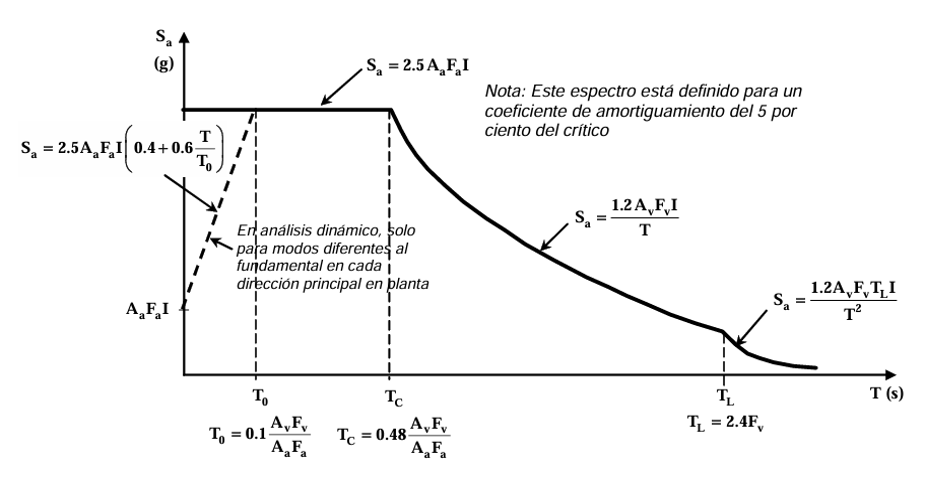






In [11]:
# ==============================================================================
# BLOQUE 5: FUERZA HORIZONTAL EQUIVALENTE (NSR-10 A.4) Y TORSIÓN ACCIDENTAL (5% B)
# ==============================================================================
import pandas as pd
import numpy as np

# ------------------------------------------------------------------------------
# 1. PANEL DE ENTRADA: PEGA AQUÍ LOS DATOS DEL BLOQUE 4
# ------------------------------------------------------------------------------
# Pega directamente el bloque que arrojó la consola del Bloque 4:
DATOS_DESDE_BLOQUE_4 = {
    "W_total": 64625.20,      # Peso sísmico total del edificio (kN)
    "h_edificio": 18.00,      # Altura total del edificio hn (m)
    "num_pisos": 5,           # Número de niveles
    "niveles": [
        {"piso": 5, "nombre": "Nivel 5 (Cubierta)", "hle": 2.70, "h_acum": 18.00, "W_nivel": 10968.80024},
        {"piso": 4, "nombre": "Nivel 4",            "hle": 2.70, "h_acum": 14.70, "W_nivel": 13142.91167},
        {"piso": 3, "nombre": "Nivel 3",            "hle": 2.70, "h_acum": 11.40, "W_nivel": 13142.91167},
        {"piso": 2, "nombre": "Nivel 2",            "hle": 2.70, "h_acum":  8.10, "W_nivel": 13142.91167},
        {"piso": 1, "nombre": "Nivel 1",            "hle": 4.50, "h_acum":  4.80, "W_nivel": 14227.66367}
    ]
}


# ------------------------------------------------------------------------------
# 2. PANEL DEL DISEÑADOR: PARÁMETROS DINÁMICOS Y DE PLANTA
# ------------------------------------------------------------------------------

# @title 🏛️ A. Sistema Estructural y Coeficientes (NSR-10 Tabla A.4.2-1)
SISTEMA_ESTRUCTURAL = "Porticos concreto resistentes a momentos"  # @param ["Porticos concreto resistentes a momentos", "Porticos acero resistentes a momentos", "Porticos arriostrados acero", "Otros sistemas con muros"]

TABLA_A42_1 = {
    "Porticos concreto resistentes a momentos": {"Ct": 0.047, "alpha": 0.90},
    "Porticos acero resistentes a momentos":    {"Ct": 0.072, "alpha": 0.80},
    "Porticos arriostrados acero":              {"Ct": 0.073, "alpha": 0.75},
    "Otros sistemas con muros":                 {"Ct": 0.049, "alpha": 0.75}
}
Ct_val    = TABLA_A42_1[SISTEMA_ESTRUCTURAL]["Ct"]
alpha_val = TABLA_A42_1[SISTEMA_ESTRUCTURAL]["alpha"]

# @title 💻 B. Periodos Modales Extraídos de SAP2000
Tx_sap = 0.575406  # @param {type:"number"}  # Periodo del modo fundamental en X (s)
Ty_sap = 0.547145  # @param {type:"number"}  # Periodo del modo fundamental en Y (s)

# @title 📐 C. Dimensiones Exteriores de la Planta (para Torsión Accidental 5% B)
Bx_total = 38.20   # @param {type:"number"}  # Dimensión total del edificio en X (m)
By_total = 26.80   # @param {type:"number"}  # Dimensión total del edificio en Y (m)

# @title ⚡ D. Aceleración espectral
# None = el código calcula Sa(T) con el espectro de la Figura A.2.6-1 (recomendado).
# Un número = Sa fija en g para ambas direcciones (solo si tienes un estudio de microzonificación).
Sa_manual = None  # @param


# ==============================================================================
# MOTOR DE CÁLCULO DEL BLOQUE 5 (MÉTODO FHE)
# ==============================================================================
hn = DATOS_DESDE_BLOQUE_4["h_edificio"]
Wt = DATOS_DESDE_BLOQUE_4["W_total"]
g  = 9.81  # m/s²

# 0. Espectro elástico de diseño (NSR-10 A.2.6, Figura A.2.6-1) con los datos del Bloque 1
Aa, Av, Fa, Fv, I_imp = b1.Aa, b1.Av, b1.Fa, b1.Fv, b1.I
T0 = 0.10 * Av * Fv / (Aa * Fa)
Tc = 0.48 * Av * Fv / (Aa * Fa)
TL = 2.40 * Fv

def Sa_espectro(T, modo_fundamental=True):
    """Sa (g) según la Figura A.2.6-1.
    Para la FHE y para el modo fundamental se usa la meseta desde T = 0;
    la rampa 0 <= T < T0 solo aplica a modos distintos al fundamental en análisis dinámico."""
    if T < T0 and not modo_fundamental:
        return 2.5 * Aa * Fa * I_imp * (0.4 + 0.6 * T / T0)
    if T <= Tc:
        return 2.5 * Aa * Fa * I_imp
    if T <= TL:
        return 1.2 * Av * Fv * I_imp / T
    return 1.2 * Av * Fv * TL * I_imp / T ** 2

# 1. Periodo aproximado Ta y límite Cu·Ta (NSR-10 A.4.2.1 y A.4.2.2)
Ta_calc = Ct_val * (hn ** alpha_val)
Cu_val = max(1.20, 1.75 - 1.20 * Av * Fv)       # Cu = 1.75 − 1.2·Av·Fv, no menor que 1.2
CuTa_lim = Cu_val * Ta_calc

def periodo_de_diseno(T_analisis):
    if T_analisis <= CuTa_lim:
        return T_analisis, "✓ SE PUEDE TOMAR (T <= Cu*Ta)"
    return CuTa_lim, f"⚠️ RIGE LÍMITE Cu*Ta = {CuTa_lim:.4f} s (T > Cu*Ta)"

Tfx, msg_x = periodo_de_diseno(Tx_sap)
Tfy, msg_y = periodo_de_diseno(Ty_sap)

# 2. Aceleración espectral y cortante basal por dirección: Vs = Sa·g·M = Sa·Wt (A.4.3.1)
Sa_x = Sa_manual if Sa_manual is not None else Sa_espectro(Tfx)
Sa_y = Sa_manual if Sa_manual is not None else Sa_espectro(Tfy)
Vs_x = round(Sa_x * Wt, 2)
Vs_y = round(Sa_y * Wt, 2)
tramo = lambda T: "meseta (T <= Tc)" if T <= Tc else ("1.2·Av·Fv·I/T" if T <= TL else "1.2·Av·Fv·TL·I/T²")

# 3. Exponente de distribución en altura k (NSR-10 A.4.3.2): k = 0.75 + 0.5·T entre 0.5 y 2.5 s
def calcular_exponente_k(T):
    if T <= 0.5:
        return 1.0
    if T >= 2.5:
        return 2.0
    return 0.75 + 0.5 * T

kx = calcular_exponente_k(Tfx)
ky = calcular_exponente_k(Tfy)

# 4. Excentricidades accidentales al 5% de la dimensión perpendicular (NSR-10 A.3.6.7.1)
dx_acc = round(0.05 * Bx_total, 2)   # brazo para Fy
dy_acc = round(0.05 * By_total, 2)   # brazo para Fx

# 5. Distribución vertical piso a piso (NSR-10 A.4.3.2)
df_fhe = pd.DataFrame(DATOS_DESDE_BLOQUE_4["niveles"])
df_fhe["m"] = df_fhe["W_nivel"] / g
df_fhe["m*h^kx"] = df_fhe["m"] * (df_fhe["h_acum"] ** kx)
df_fhe["m*h^ky"] = df_fhe["m"] * (df_fhe["h_acum"] ** ky)
df_fhe["Cvx"] = df_fhe["m*h^kx"] / df_fhe["m*h^kx"].sum()
df_fhe["Cvy"] = df_fhe["m*h^ky"] / df_fhe["m*h^ky"].sum()
df_fhe["Fx [kN]"] = round(df_fhe["Cvx"] * Vs_x, 2)
df_fhe["Fy [kN]"] = round(df_fhe["Cvy"] * Vs_y, 2)
df_fhe["MzFx [kN*m]"] = round(df_fhe["Fx [kN]"] * dy_acc, 2)
df_fhe["MzFy [kN*m]"] = round(df_fhe["Fy [kN]"] * dx_acc, 2)

# Cortante de piso acumulado desde la cubierta (lo usan los bloques de derivas e irregularidades)
df_fhe = df_fhe.sort_values(by="piso", ascending=False).reset_index(drop=True)
df_fhe["Vx piso [kN]"] = df_fhe["Fx [kN]"].cumsum().round(2)
df_fhe["Vy piso [kN]"] = df_fhe["Fy [kN]"].cumsum().round(2)

sum_Fx = round(df_fhe["Fx [kN]"].sum(), 2)
sum_Fy = round(df_fhe["Fy [kN]"].sum(), 2)
sum_MzFx = round(df_fhe["MzFx [kN*m]"].sum(), 2)
sum_MzFy = round(df_fhe["MzFy [kN*m]"].sum(), 2)


# ------------------------------------------------------------------------------
# 6. DESPLIEGUE DE RESULTADOS EN PANTALLA
# ------------------------------------------------------------------------------
print("=" * 115)
print("PARÁMETROS DEL MÉTODO DE LA FUERZA HORIZONTAL EQUIVALENTE (NSR-10 A.4 / HOJA FHE):")
print("=" * 115)
print(f"• Altura total del edificio (hn) : {hn:.2f} m  |  Peso Sísmico Total (Wt) : {Wt:.2f} kN")
print(f"• Espectro (Bloque 1)            : T0 = {T0:.4f} s | Tc = {Tc:.4f} s | TL = {TL:.4f} s")
print(f"• Periodo aproximado Ta          : {Ta_calc:.4f} s (Ct = {Ct_val}, α = {alpha_val})")
print(f"• Cu = max(1.2, 1.75 − 1.2·Av·Fv): {Cu_val:.3f}  -->  Límite Cu*Ta = {CuTa_lim:.4f} s")
print(f"• Periodo en X (SAP2000)         : Tx = {Tx_sap:.6f} s --> Tfx = {Tfx:.6f} s | {msg_x}")
print(f"• Periodo en Y (SAP2000)         : Ty = {Ty_sap:.6f} s --> Tfy = {Tfy:.6f} s | {msg_y}")
print(f"• Sa en X                        : {Sa_x:.5f} g  [{tramo(Tfx)}]")
print(f"• Sa en Y                        : {Sa_y:.5f} g  [{tramo(Tfy)}]")
print(f"• Exponentes de altura (A.4.3.2) : kx = {kx:.6f}  |  ky = {ky:.6f}")
print(f"• Cortante basal (Vs = Sa·Wt)    : Vsx = {Vs_x:.2f} kN  |  Vsy = {Vs_y:.2f} kN")
print(f"• Excentricidades accidentales   : dx = 5% Bx = {dx_acc:.2f} m  |  dy = 5% By = {dy_acc:.2f} m")
print("=" * 115)

print("\nTABLA MAESTRA DE FUERZAS SÍSMICAS LATERALES Y TORSIÓN ACCIDENTAL:")
print("-" * 115)
columnas_ver = ["piso", "nombre", "h_acum", "W_nivel", "Cvx", "Fx [kN]", "Vx piso [kN]", "MzFx [kN*m]",
                "Cvy", "Fy [kN]", "Vy piso [kN]", "MzFy [kN*m]"]
df_ordenado = df_fhe
print(df_ordenado[columnas_ver].round(4).to_string(index=False))
print("-" * 115)
print(f"TOTAL SUMATORIA VERIFICADA: Fx = {sum_Fx:.2f} kN (Vsx)  |  Fy = {sum_Fy:.2f} kN (Vsy)")
print(f"TOTAL MOMENTOS TORSORES   : MzFx = {sum_MzFx:.2f} kN*m  |  MzFy = {sum_MzFy:.2f} kN*m")
print("=" * 115)

# ------------------------------------------------------------------------------
# 7. GUÍA DIRECTA DE ASIGNACIÓN EN SAP2000
# ------------------------------------------------------------------------------
print("\n" + "=" * 90)
print("📌 GUÍA PARA CARGAR EN SAP2000 (Assign > Joint Loads > Forces):")
print("   Asignar en el nudo del Centro de Masa (Xcm, Ycm) de cada Diafragma Rígido.")
print("   Crea 4 patrones: SX+ (Fx, +Mz), SX- (Fx, −Mz), SY+ (Fy, +Mz), SY- (Fy, −Mz).")
print("   Estas son fuerzas Fs SIN dividir por R: se usan tal cual para derivas (Bloque 7)")
print("   y se dividen por R en las combinaciones de diseño (Bloque 9).")
print("=" * 90)
for _, r in df_ordenado.iterrows():
    print(f"\n🏢 {r['nombre']} (Cota Z = {r['h_acum']:.2f} m):")
    print(f"   • SX±: Force Global X = {r['Fx [kN]']:>9.2f} kN  |  Moment Global Z = ±{r['MzFx [kN*m]']:>10.2f} kN*m")
    print(f"   • SY±: Force Global Y = {r['Fy [kN]']:>9.2f} kN  |  Moment Global Z = ±{r['MzFy [kN*m]']:>10.2f} kN*m")
print("=" * 90)


PARÁMETROS DEL MÉTODO DE LA FUERZA HORIZONTAL EQUIVALENTE (NSR-10 A.4 / HOJA FHE):
• Altura total del edificio (hn) : 18.00 m  |  Peso Sísmico Total (Wt) : 64625.20 kN
• Espectro (Bloque 1)            : T0 = 0.1342 s | Tc = 0.6440 s | TL = 4.3200 s
• Periodo aproximado Ta          : 0.6336 s (Ct = 0.047, α = 0.9)
• Cu = max(1.2, 1.75 − 1.2·Av·Fv): 1.200  -->  Límite Cu*Ta = 0.7604 s
• Periodo en X (SAP2000)         : Tx = 0.575406 s --> Tfx = 0.575406 s | ✓ SE PUEDE TOMAR (T <= Cu*Ta)
• Periodo en Y (SAP2000)         : Ty = 0.547145 s --> Tfy = 0.547145 s | ✓ SE PUEDE TOMAR (T <= Cu*Ta)
• Sa en X                        : 1.00625 g  [meseta (T <= Tc)]
• Sa en Y                        : 1.00625 g  [meseta (T <= Tc)]
• Exponentes de altura (A.4.3.2) : kx = 1.037703  |  ky = 1.023572
• Cortante basal (Vs = Sa·Wt)    : Vsx = 65029.11 kN  |  Vsy = 65029.11 kN
• Excentricidades accidentales   : dx = 5% Bx = 1.91 m  |  dy = 5% By = 1.34 m

TABLA MAESTRA DE FUERZAS SÍSMICAS LATERALES Y TORSIÓN 

---
## 📈 BLOQUE 6: ESPECTRO PARA SAP2000 (NSR-10 A.2.6)
 │   └─► Genera la tabla T–Sa (archivo .txt) para el caso modal espectral y la gráfica con Tfx y Tfy.


TABLA DEL ESPECTRO (primeras filas) — archivo completo: espectro_NSR10_SAP2000.txt
 T [s]  Sa [g]
0.0000 0.40250
0.0500 0.62751
0.1000 0.85252
0.1342 1.00625
0.1500 1.00625
0.2000 1.00625
0.2500 1.00625
0.3000 1.00625
0.3500 1.00625
0.4000 1.00625
0.4500 1.00625
0.5000 1.00625
...

📌 GUÍA SAP2000 PARA EL ANÁLISIS DINÁMICO (NSR-10 A.5):
   1. Define > Functions > Response Spectrum > From File: carga el .txt (Period vs Value), damping 0.05.
   2. Define > Load Cases > Modal: modos suficientes para ≥ 90 % de masa participativa en X y en Y (A.5.4.2).
   3. Define > Load Cases > Response Spectrum: casos DX (U1) y DY (U2), combinación modal CQC,
      direccional SRSS, factor de escala = g = 9.81 m/s², excentricidad accidental 0.05.
   4. Corre el modelo y lleva al Bloque 10 la tabla modal y los cortantes basales dinámicos.


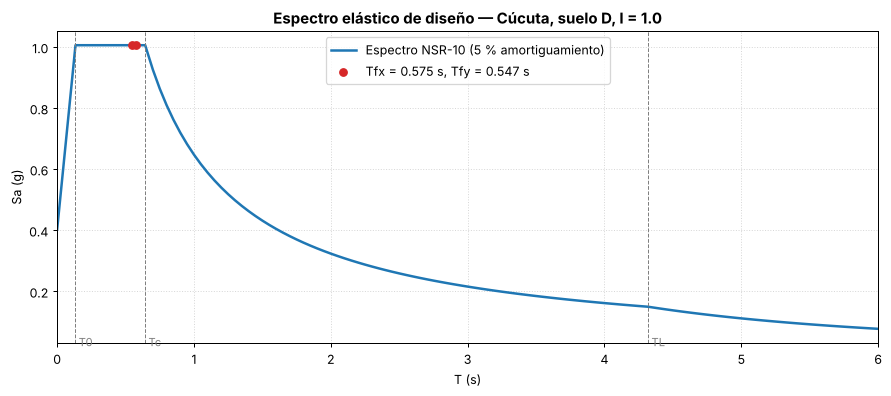

In [12]:
# ==============================================================================
# BLOQUE 6: ESPECTRO DE DISEÑO PARA SAP2000 Y CASO MODAL ESPECTRAL (NSR-10 A.2.6 / A.5)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. PANEL DEL DISEÑADOR
# ------------------------------------------------------------------------------
T_MAX_ESPECTRO = 6.0   # s, último periodo de la tabla
PASO_T = 0.05          # s, paso de la tabla (SAP interpola linealmente entre puntos)

# ------------------------------------------------------------------------------
# 2. MOTOR: TABLA T–Sa (con la rampa 0–T0 para modos no fundamentales)
# ------------------------------------------------------------------------------
T_puntos = sorted(set([0.0, round(T0, 4), round(Tc, 4), round(TL, 4)] +
                      [round(t, 4) for t in np.arange(PASO_T, T_MAX_ESPECTRO + 1e-9, PASO_T)]))
df_espectro = pd.DataFrame({"T [s]": T_puntos,
                            "Sa [g]": [round(Sa_espectro(t, modo_fundamental=False), 5) for t in T_puntos]})

# Archivo de texto listo para SAP2000 (Define > Functions > Response Spectrum > From File)
ARCHIVO_ESPECTRO = "espectro_NSR10_SAP2000.txt"
df_espectro.to_csv(ARCHIVO_ESPECTRO, sep="\t", index=False, header=False)

# ------------------------------------------------------------------------------
# 3. GRÁFICA
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_espectro["T [s]"], df_espectro["Sa [g]"], color="#1f77b4", lw=2, label="Espectro NSR-10 (5 % amortiguamiento)")
for T_lin, nombre in [(T0, "T0"), (Tc, "Tc"), (TL, "TL")]:
    ax.axvline(T_lin, color="grey", ls="--", lw=0.8)
    ax.text(T_lin, ax.get_ylim()[1] * 0.02 if ax.get_ylim()[1] else 0, f" {nombre}", color="grey", fontsize=9)
ax.scatter([Tfx, Tfy], [Sa_x, Sa_y], color="#d62728", zorder=5, label=f"Tfx = {Tfx:.3f} s, Tfy = {Tfy:.3f} s")
ax.set_xlabel("T (s)"); ax.set_ylabel("Sa (g)"); ax.set_xlim(0, min(T_MAX_ESPECTRO, max(3.0, 1.5 * TL)))
ax.set_title(f"Espectro elástico de diseño — {b1.ciudad}, suelo {b1.tipo_suelo}, I = {I_imp}", fontweight="bold")
ax.grid(True, ls=":", alpha=0.5); ax.legend()
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------------------
# 4. SALIDA
# ------------------------------------------------------------------------------
print("=" * 90)
print("TABLA DEL ESPECTRO (primeras filas) — archivo completo:", ARCHIVO_ESPECTRO)
print("=" * 90)
print(df_espectro.head(12).to_string(index=False))
print("...")
print("\n📌 GUÍA SAP2000 PARA EL ANÁLISIS DINÁMICO (NSR-10 A.5):")
print("   1. Define > Functions > Response Spectrum > From File: carga el .txt (Period vs Value), damping 0.05.")
print("   2. Define > Load Cases > Modal: modos suficientes para ≥ 90 % de masa participativa en X y en Y (A.5.4.2).")
print("   3. Define > Load Cases > Response Spectrum: casos DX (U1) y DY (U2), combinación modal CQC,")
print("      direccional SRSS, factor de escala = g = 9.81 m/s², excentricidad accidental 0.05.")
print("   4. Corre el modelo y lleva al Bloque 10 la tabla modal y los cortantes basales dinámicos.")
print("=" * 90)


---
## 📐 BLOQUE 7: DERIVAS CON TORSIÓN Y P-DELTA (NSR-10 A.6)
 │   └─► Pegas desplazamientos del CM (SX+, SY+) desde SAP2000. Obtienes Q, derivas en esquinas y dictamen 1.0 % hpi.


In [13]:
# ==============================================================================
# BLOQUE 7: DERIVAS DE PISO CON TORSIÓN Y EFECTO P-DELTA (NSR-10 A.6)
# ==============================================================================
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANEL DE ENTRADA: DESPLAZAMIENTOS DEL CENTRO DE MASA DESDE SAP2000
# ------------------------------------------------------------------------------
# Display > Show Tables > Joint Output > Joint Displacements, en el nudo maestro (CM) de cada piso,
# para los patrones SX+ y SY+ del Bloque 5 (fuerzas Fs SIN dividir por R, con torsión accidental).
# Ux, Uy en metros; Rz en radianes. Piso 1 = primer nivel sobre la base.
#
# ⚠️ VALORES DE EJEMPLO — NO SON RESULTADOS REALES DEL V7. REEMPLÁZALOS POR LOS DE TU MODELO
#    y cambia DATOS_SAP_SON_EJEMPLO a False (también lo usan los Bloques 8, 10 y 11).
DATOS_SAP_SON_EJEMPLO = True
DESPLAZAMIENTOS_CM_SAP = {
    #  piso: {"SX": (Ux, Uy, Rz),            "SY": (Ux, Uy, Rz)}
    1: {"SX": (0.0300, 0.0010, 0.00020), "SY": (0.0010, 0.0270, 0.00025)},
    2: {"SX": (0.0550, 0.0018, 0.00035), "SY": (0.0018, 0.0500, 0.00042)},
    3: {"SX": (0.0770, 0.0024, 0.00048), "SY": (0.0024, 0.0700, 0.00056)},
    4: {"SX": (0.0950, 0.0029, 0.00058), "SY": (0.0029, 0.0860, 0.00067)},
    5: {"SX": (0.1080, 0.0032, 0.00064), "SY": (0.0032, 0.0980, 0.00074)},
}

# Límite de deriva (NSR-10 Tabla A.6.4-1): 1.0 % de hpi para concreto reforzado, metálicas y madera
# (0.5 % si la estructura es de mampostería).
DERIVA_LIMITE = 0.010

# ------------------------------------------------------------------------------
# 2. DATOS QUE VIENEN DE BLOQUES ANTERIORES (no editar)
# ------------------------------------------------------------------------------
# Esquinas del perímetro de losa (Bloque 3A) y centro de masa:
esquinas = vert_ext                      # lista de (x, y) del contorno exterior
xcm, ycm = X_CM, Y_CM
# Alturas de nivel, pesos y cortantes de piso (Bloques 4 y 5):
niv = df_fhe.sort_values("piso").reset_index(drop=True)
h_niv = dict(zip(niv["piso"], niv["h_acum"]))
# Carga vertical sin mayorar por nivel: muerta (W_nivel) + viva sobre el área de planta
A_planta = DATOS_DESDE_BLOQUE_3["A_bruta_losa"]
wL_ent, wL_cub = DATOS_DESDE_BLOQUE_3["wL_ent"], DATOS_DESDE_BLOQUE_3["wL_cub"]
n_top = int(niv["piso"].max())
P_nivel = {int(r.piso): r.W_nivel + (wL_cub if r.piso == n_top else wL_ent) * A_planta for r in niv.itertuples()}

# ------------------------------------------------------------------------------
# 3. MOTOR DE CÁLCULO
# ------------------------------------------------------------------------------
def desplazamiento_punto(U, x, y):
    """Diafragma rígido: desplazamiento de un punto (x, y) a partir del CM (A.6.3.1)."""
    ux, uy, rz = U
    return ux - rz * (y - ycm), uy + rz * (x - xcm)

filas = []
for caso, comp in (("SX", 0), ("SY", 1)):
    V_col = "Vx piso [kN]" if caso == "SX" else "Vy piso [kN]"
    for i in sorted(DESPLAZAMIENTOS_CM_SAP):
        U_i = DESPLAZAMIENTOS_CM_SAP[i][caso]
        U_b = DESPLAZAMIENTOS_CM_SAP[i - 1][caso] if i > 1 else (0.0, 0.0, 0.0)
        hpi = h_niv[i] - (h_niv[i - 1] if i > 1 else 0.0)

        # a) Índice de estabilidad Q (A.6.2.3) con el desplazamiento del CM en la dirección del sismo
        P_i = sum(P_nivel[j] for j in P_nivel if j >= i)          # carga vertical sobre el piso i
        V_i = float(niv.loc[niv["piso"] == i, V_col].iloc[0])
        d_cm = U_i[comp] - U_b[comp]
        Q = P_i * abs(d_cm) / (V_i * hpi)
        f_pd = 1.0 if Q <= 0.10 else (1.0 / (1.0 - Q) if Q <= 0.30 else float("nan"))

        # b) Deriva máxima en las esquinas: Δ = √[(Δx)² + (Δy)²] (Ec. A.6.3-1), amplificada por P-Delta
        derivas = []
        for (x, y) in esquinas:
            ux_i, uy_i = desplazamiento_punto(U_i, x, y)
            ux_b, uy_b = desplazamiento_punto(U_b, x, y)
            derivas.append(((x, y), np.hypot(ux_i - ux_b, uy_i - uy_b) * f_pd, (ux_i - ux_b, uy_i - uy_b)))
        (x_m, y_m), D_max, _ = max(derivas, key=lambda t: t[1])
        D_cm = np.hypot(U_i[0] - U_b[0], U_i[1] - U_b[1]) * f_pd

        filas.append({
            "Caso": caso, "Piso": i, "hpi [m]": round(hpi, 3),
            "P [kN]": round(P_i, 1), "V [kN]": round(V_i, 1), "Q": round(Q, 4),
            "Factor P-Δ": round(f_pd, 3) if f_pd == f_pd else "INESTABLE",
            "Δcm [m]": round(D_cm, 5), "Δmax esquina [m]": round(D_max, 5),
            "Esquina crítica": f"({x_m:.1f}, {y_m:.1f})",
            "Deriva [%hpi]": round(100 * D_max / hpi, 3),
            "Límite [%]": 100 * DERIVA_LIMITE,
            "Cumple": "✓" if D_max <= DERIVA_LIMITE * hpi else "✗ NO CUMPLE",
            # componentes en la dirección del sismo en los dos extremos (para torsión en el Bloque 8)
            "_comp_extremos": [d[2][comp] for d in derivas],
        })

df_derivas = pd.DataFrame(filas)
deriva_max_x = df_derivas.loc[df_derivas["Caso"] == "SX", "Deriva [%hpi]"].max()
deriva_max_y = df_derivas.loc[df_derivas["Caso"] == "SY", "Deriva [%hpi]"].max()
cumple_derivas = bool((df_derivas["Cumple"] == "✓").all())
hay_inestabilidad = bool((df_derivas["Factor P-Δ"] == "INESTABLE").any())

# ------------------------------------------------------------------------------
# 4. RESULTADOS
# ------------------------------------------------------------------------------
print("=" * 120)
print("CONTROL DE DERIVAS NSR-10 A.6 (desplazamientos del CM trasladados a las esquinas, diafragma rígido)")
if DATOS_SAP_SON_EJEMPLO:
    print("⚠️  DESPLAZAMIENTOS DE EJEMPLO: estos resultados son solo ilustrativos.")
print("=" * 120)
print(df_derivas.drop(columns=["_comp_extremos"]).to_string(index=False))
print("-" * 120)
print(f"• Deriva máxima en X: {deriva_max_x:.3f} % | en Y: {deriva_max_y:.3f} % | límite {100*DERIVA_LIMITE:.1f} %")
print(f"• Índice de estabilidad: Q ≤ 0.10 se ignora P-Δ; 0.10 < Q ≤ 0.30 se amplifica por 1/(1−Q); Q > 0.30 inestable (A.6.2.3)")
if hay_inestabilidad:
    print("  ✗ HAY PISOS CON Q > 0.30: LA ESTRUCTURA ES INESTABLE Y DEBE RIGIDIZARSE.")
print(f"• DICTAMEN DERIVAS: {'✓ CUMPLE' if cumple_derivas else '✗ NO CUMPLE — aumentar secciones de columnas/vigas y volver a correr SAP2000'}")
print("=" * 120)


CONTROL DE DERIVAS NSR-10 A.6 (desplazamientos del CM trasladados a las esquinas, diafragma rígido)
⚠️  DESPLAZAMIENTOS DE EJEMPLO: estos resultados son solo ilustrativos.
Caso  Piso  hpi [m]  P [kN]  V [kN]      Q  Factor P-Δ  Δcm [m]  Δmax esquina [m] Esquina crítica  Deriva [%hpi]  Límite [%] Cumple
  SX     1      4.8 87578.7 65029.1 0.0084         1.0  0.03002           0.03282     (38.2, 0.0)          0.684         1.0      ✓
  SX     2      3.3 68760.3 59033.6 0.0088         1.0  0.02501           0.02710     (38.2, 0.0)          0.821         1.0      ✓
  SX     3      3.3 51026.7 49501.3 0.0069         1.0  0.02201           0.02380     (38.2, 0.0)          0.721         1.0      ✓
  SX     4      3.3 33293.1 35911.5 0.0051         1.0  0.01801           0.01938     (38.2, 0.0)          0.587         1.0      ✓
  SX     5      3.3 15559.5 18219.1 0.0034         1.0  0.01300           0.01382     (38.2, 0.0)          0.419         1.0      ✓
  SY     1      4.8 87578.7 65029.1 

---
## 🧩 BLOQUE 8: IRREGULARIDADES Y COEFICIENTE R (NSR-10 A.3.3)
 │   └─► Torsional (1aP/1bP), retrocesos (2P), diafragma (3P), piso flexible (1aA/1bA), masa (2A). R = φa·φp·φr·R0.


In [14]:
# ==============================================================================
# BLOQUE 8: IRREGULARIDADES (NSR-10 A.3.3) Y COEFICIENTE DE DISIPACIÓN R
# ==============================================================================
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANEL DEL DISEÑADOR
# ------------------------------------------------------------------------------
# A. Capacidad de disipación de energía del sistema (pórticos de concreto resistentes a momento)
CAPACIDAD_DISIPACION = "DES"   # @param ["DES", "DMO", "DMI"]

# B. Retroceso en esquina (irregularidad 2P): proyección del entrante respecto a la dimensión total.
#    Para el V7 (polígono del Bloque 3A): el entrante superior izquierdo mide 23.8 m en X y 4.9 m en Y.
PROYECCION_ENTRANTE_X = 23.80   # m (0 si no hay retrocesos)
PROYECCION_ENTRANTE_Y = 4.90    # m

# C. Irregularidades que este notebook no puede medir solo (marca True si aplican):
IRREG_MANUAL = {
    "4P Desplazamiento del plano de acción":        False,
    "5P Sistemas no paralelos":                      False,
    "3A Geométrica (planta > 1.3 veces la contigua)": False,
    "4A Desplazamiento dentro del plano de acción":  False,
    "5aA Piso débil (resistencia < 80 % del superior)": False,
}

# D. Redundancia (NSR-10 A.3.3.8). En zonas de amenaza intermedia y alta, φr = 0.75 si al retirar un
#    elemento la resistencia del piso cae más de 33 % o aparece torsión extrema; si no, 1.0.
PHI_R = 1.00   # @param {type:"number"}

# ------------------------------------------------------------------------------
# 2. MOTOR DE CÁLCULO
# ------------------------------------------------------------------------------
TABLA_A3_3 = {"DES": {"R0": 7.0, "Omega0": 3.0, "zonas": ["Alta", "Intermedia", "Baja"]},
              "DMO": {"R0": 5.0, "Omega0": 3.0, "zonas": ["Intermedia", "Baja"]},
              "DMI": {"R0": 2.5, "Omega0": 3.0, "zonas": ["Baja"]}}
sis = TABLA_A3_3[CAPACIDAD_DISIPACION]
R0, Omega0 = sis["R0"], sis["Omega0"]
zona_ok = any(z in b1.zona for z in sis["zonas"]) or "Personalizada" in b1.zona

hallazgos = []   # (código, descripción, φ, tipo)

# --- Planta ---
# 1aP / 1bP Torsional: deriva del extremo más cargado vs promedio de los dos extremos (con torsión accidental)
xs = [p[0] for p in esquinas]; ys = [p[1] for p in esquinas]
filas_tor = []
for _, r in df_derivas.iterrows():
    comps = np.abs(np.array(r["_comp_extremos"]))
    coord = ys if r["Caso"] == "SX" else xs           # extremos perpendiculares a la dirección del sismo
    lado1 = comps[[k for k, c in enumerate(coord) if c == min(coord)]].max()
    lado2 = comps[[k for k, c in enumerate(coord) if c == max(coord)]].max()
    prom = (lado1 + lado2) / 2.0
    ratio = max(lado1, lado2) / prom if prom > 0 else 1.0
    filas_tor.append({"Caso": r["Caso"], "Piso": r["Piso"], "Δ extremo 1 [m]": round(lado1, 5),
                      "Δ extremo 2 [m]": round(lado2, 5), "Δmax/Δprom": round(ratio, 3)})
df_torsion = pd.DataFrame(filas_tor)
ratio_tor = df_torsion["Δmax/Δprom"].max()
if ratio_tor > 1.4:
    hallazgos.append(("1bP", f"Torsional extrema (Δmax/Δprom = {ratio_tor:.2f} > 1.4)", 0.8, "planta"))
elif ratio_tor > 1.2:
    hallazgos.append(("1aP", f"Torsional (Δmax/Δprom = {ratio_tor:.2f} > 1.2)", 0.9, "planta"))

# 2P Retrocesos en las esquinas: ambas proyecciones > 15 % de la dimensión en esa dirección
Lx_planta, Ly_planta = max(xs) - min(xs), max(ys) - min(ys)
px, py = PROYECCION_ENTRANTE_X / Lx_planta, PROYECCION_ENTRANTE_Y / Ly_planta
if px > 0.15 and py > 0.15:
    hallazgos.append(("2P", f"Retroceso en esquina ({100*px:.0f} % en X y {100*py:.0f} % en Y > 15 %)", 0.9, "planta"))

# 3P Discontinuidad del diafragma: aberturas > 50 % del área bruta
A_huecos = sum(calcular_gauss(h)[0] for h in huecos_coords)
A_bruta_poly = calcular_gauss(vert_ext)[0]
if A_huecos / A_bruta_poly > 0.50:
    hallazgos.append(("3P", f"Aberturas del diafragma {100*A_huecos/A_bruta_poly:.0f} % > 50 %", 0.9, "planta"))

# --- Altura ---
# 1aA / 1bA Piso flexible: rigidez de piso k = V / Δcm en cada dirección
filas_rig = []
for caso, comp, Vcol in (("SX", 0, "Vx piso [kN]"), ("SY", 1, "Vy piso [kN]")):
    k = {}
    for i in sorted(DESPLAZAMIENTOS_CM_SAP):
        U_i = DESPLAZAMIENTOS_CM_SAP[i][caso][comp]
        U_b = DESPLAZAMIENTOS_CM_SAP[i - 1][caso][comp] if i > 1 else 0.0
        k[i] = float(niv.loc[niv["piso"] == i, Vcol].iloc[0]) / abs(U_i - U_b)
    for i in sorted(k):
        sup = [k[j] for j in range(i + 1, i + 4) if j in k]
        r1 = k[i] / k[i + 1] if (i + 1) in k else None
        r3 = k[i] / np.mean(sup) if len(sup) == 3 else None
        filas_rig.append({"Caso": caso, "Piso": i, "k [kN/m]": round(k[i], 0),
                          "k / k superior": round(r1, 3) if r1 else "-",
                          "k / prom. 3 superiores": round(r3, 3) if r3 else "-"})
df_rigidez = pd.DataFrame(filas_rig)
r1_min = min([v for v in df_rigidez["k / k superior"] if v != "-"], default=1.0)
r3_min = min([v for v in df_rigidez["k / prom. 3 superiores"] if v != "-"], default=1.0)
if r1_min < 0.60 or r3_min < 0.70:
    hallazgos.append(("1bA", f"Piso flexible extremo (k/k_sup = {r1_min:.2f}, k/prom3 = {r3_min:.2f})", 0.8, "altura"))
elif r1_min < 0.70 or r3_min < 0.80:
    hallazgos.append(("1aA", f"Piso flexible (k/k_sup = {r1_min:.2f}, k/prom3 = {r3_min:.2f})", 0.9, "altura"))

# 2A Distribución de masa: masa de un piso > 1.5 veces la de un piso contiguo (cubierta más liviana exenta)
W = dict(zip(niv["piso"], niv["W_nivel"]))
for i in sorted(W):
    for j in (i - 1, i + 1):
        if j in W and W[i] > 1.5 * W[j] and not (j == n_top and W[j] < W[i]):
            hallazgos.append(("2A", f"Masa del piso {i} > 1.5 × piso {j}", 0.9, "altura"))
            break

# Manuales
phi_manual = {"4P": 0.8, "5P": 0.9, "3A": 0.9, "4A": 0.8, "5aA": 0.9}
for nombre, activo in IRREG_MANUAL.items():
    if activo:
        cod = nombre.split()[0]
        hallazgos.append((cod, nombre + " (indicada por el diseñador)", phi_manual[cod], "planta" if cod.endswith("P") else "altura"))

phi_p = min([h[2] for h in hallazgos if h[3] == "planta"], default=1.0)
phi_a = min([h[2] for h in hallazgos if h[3] == "altura"], default=1.0)
R_diseno = round(phi_a * phi_p * PHI_R * R0, 3)
es_irregular = phi_p < 1.0 or phi_a < 1.0

# ------------------------------------------------------------------------------
# 3. RESULTADOS
# ------------------------------------------------------------------------------
print("=" * 100)
print("IRREGULARIDADES NSR-10 A.3.3 Y COEFICIENTE DE DISIPACIÓN R")
print("=" * 100)
print("\n1. Torsión (Tabla A.3-6, tipos 1aP / 1bP):")
print(df_torsion.to_string(index=False))
print("\n2. Rigidez de piso (Tabla A.3-7, tipos 1aA / 1bA):")
print(df_rigidez.to_string(index=False))
print("\n3. Irregularidades encontradas:")
if hallazgos:
    for cod, desc, phi, tipo in hallazgos:
        print(f"   • {cod:4s} [{tipo}]  {desc}  →  φ = {phi}")
else:
    print("   • Ninguna: estructura regular en planta y en altura.")
print("-" * 100)
print(f"• Sistema: pórtico de concreto {CAPACIDAD_DISIPACION}  →  R0 = {R0}, Ω0 = {Omega0} (Tabla A.3-3)")
print(f"• Zona de amenaza ({b1.zona}): {'✓ permitido' if zona_ok else '✗ NO PERMITIDO para esta zona — usar mayor capacidad de disipación'}")
print(f"• φp = {phi_p} | φa = {phi_a} | φr = {PHI_R}")
print(f"• R = φa · φp · φr · R0 = {phi_a} × {phi_p} × {PHI_R} × {R0} = {R_diseno}")
print(f"• Clasificación: {'IRREGULAR' if es_irregular else 'REGULAR'}")
print("=" * 100)
if DATOS_SAP_SON_EJEMPLO:
    print("⚠️ Torsión y piso flexible usan desplazamientos de EJEMPLO: el resultado es ilustrativo.")


IRREGULARIDADES NSR-10 A.3.3 Y COEFICIENTE DE DISIPACIÓN R

1. Torsión (Tabla A.3-6, tipos 1aP / 1bP):
Caso  Piso  Δ extremo 1 [m]  Δ extremo 2 [m]  Δmax/Δprom
  SX     1          0.03249          0.02713       1.090
  SX     2          0.02687          0.02285       1.081
  SX     3          0.02362          0.02013       1.080
  SX     4          0.01924          0.01656       1.075
  SX     5          0.01375          0.01214       1.062
  SY     1          0.02200          0.03155       1.178
  SY     2          0.01960          0.02610       1.142
  SY     3          0.01720          0.02255       1.135
  SY     4          0.01380          0.01800       1.132
  SY     5          0.01060          0.01327       1.112

2. Rigidez de piso (Tabla A.3-7, tipos 1aA / 1bA):
Caso  Piso  k [kN/m] k / k superior k / prom. 3 superiores
  SX     1 2167637.0          0.918                  0.984
  SX     2 2361344.0          1.049                  1.255
  SX     3 2250060.0          1.128      

---
## ➕ BLOQUE 9: COMBINACIONES DE CARGA (NSR-10 B.2.4 + A.3.6.3)
 │   └─► Genera las combinaciones de diseño con E = Fs/R y 100 % + 30 % ortogonal; exporta CSV para SAP2000.


In [15]:
# ==============================================================================
# BLOQUE 9: COMBINACIONES DE CARGA NSR-10 (B.2.4) PARA SAP2000, CON E = Fs / R
# ==============================================================================
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANEL DEL DISEÑADOR
# ------------------------------------------------------------------------------
# Nombres de los patrones/casos tal como están en SAP2000:
CASO_D = "DEAD"     # muerta (peso propio + sobreimpuesta)
CASO_L = "LIVE"     # viva
PATRONES_SISMO = {"SX+": "SX+", "SX-": "SX-", "SY+": "SY+", "SY-": "SY-"}   # del Bloque 5 (fuerzas Fs)

# Factor de L en las combinaciones con sismo (B.2.4-5). 1.0 por defecto; la NSR-10 permite 0.5
# salvo garajes, áreas de reunión pública y zonas con L > 4.8 kN/m². Revisa antes de cambiarlo.
FACTOR_L_SISMO = 1.0

# Efectos ortogonales (NSR-10 A.3.6.3): 100 % en una dirección + 30 % en la otra
PORC_ORTOGONAL = 0.30

# ------------------------------------------------------------------------------
# 2. MOTOR: GENERACIÓN DE COMBINACIONES
# ------------------------------------------------------------------------------
fE = round(1.0 / R_diseno, 5)     # las fuerzas Fs se dividen por R (A.3.1 / A.3.4)
combos = []

def agregar(nombre, terminos, origen):
    for caso, factor in terminos:
        combos.append({"Combinación": nombre, "Caso / patrón": caso, "Factor": round(factor, 5), "Referencia": origen})

agregar("U1_1.4D", [(CASO_D, 1.4)], "B.2.4-1")
agregar("U2_1.2D+1.6L", [(CASO_D, 1.2), (CASO_L, 1.6)], "B.2.4-2")

n = 3
for principal, secundaria in (("X", "Y"), ("Y", "X")):
    for ecc in ("+", "-"):
        for s1 in (+1, -1):
            for s2 in (+1, -1):
                pat_p = PATRONES_SISMO[f"S{principal}{ecc}"]
                pat_s = PATRONES_SISMO[f"S{secundaria}{ecc}"]
                sismo = [(pat_p, s1 * fE), (pat_s, s2 * PORC_ORTOGONAL * fE)]
                etiqueta = f"{'+' if s1 > 0 else '-'}E{principal}(e{ecc}){'+' if s2 > 0 else '-'}0.3E{secundaria}"
                agregar(f"U{n}_1.2D+{FACTOR_L_SISMO:g}L{etiqueta}", [(CASO_D, 1.2), (CASO_L, FACTOR_L_SISMO)] + sismo, "B.2.4-5 + A.3.6.3")
                n += 1
                agregar(f"U{n}_0.9D{etiqueta}", [(CASO_D, 0.9)] + sismo, "B.2.4-7 + A.3.6.3")
                n += 1

df_combos = pd.DataFrame(combos)
ARCHIVO_COMBOS = "combinaciones_NSR10_SAP2000.csv"
df_combos.to_csv(ARCHIVO_COMBOS, index=False, encoding="utf-8-sig")
n_combos = df_combos["Combinación"].nunique()

# ------------------------------------------------------------------------------
# 3. RESULTADOS
# ------------------------------------------------------------------------------
print("=" * 100)
print(f"COMBINACIONES DE DISEÑO NSR-10 — R = {R_diseno}  →  factor sísmico 1/R = {fE}")
print("=" * 100)
resumen = pd.DataFrame(
    [{"Combinación": nombre, "Definición": " + ".join(f"{f:g}·{c}" for c, f in zip(d["Caso / patrón"], d["Factor"]))}
     for nombre, d in df_combos.groupby("Combinación", sort=False)])
print(resumen.head(8).to_string(index=False))
print(f"... {n_combos} combinaciones en total. Archivo para SAP2000: {ARCHIVO_COMBOS}")
print("\n📌 En SAP2000: Define > Load Combinations > Add New Combo (Linear Add), o importa la tabla")
print("   'Combination Definitions' con el CSV. Crea además una envolvente ENV_DISEÑO con todas las U*.")
print("📌 Las derivas (Bloque 7) se revisan con los patrones SX±/SY± sin dividir por R; no uses estas combinaciones para eso.")
print("=" * 100)


COMBINACIONES DE DISEÑO NSR-10 — R = 6.3  →  factor sísmico 1/R = 0.15873
            Combinación                                     Definición
                U1_1.4D                                       1.4·DEAD
           U2_1.2D+1.6L                            1.2·DEAD + 1.6·LIVE
U3_1.2D+1L+EX(e+)+0.3EY  1.2·DEAD + 1·LIVE + 0.15873·SX+ + 0.04762·SY+
   U4_0.9D+EX(e+)+0.3EY           0.9·DEAD + 0.15873·SX+ + 0.04762·SY+
U5_1.2D+1L+EX(e+)-0.3EY 1.2·DEAD + 1·LIVE + 0.15873·SX+ + -0.04762·SY+
   U6_0.9D+EX(e+)-0.3EY          0.9·DEAD + 0.15873·SX+ + -0.04762·SY+
U7_1.2D+1L-EX(e+)+0.3EY 1.2·DEAD + 1·LIVE + -0.15873·SX+ + 0.04762·SY+
   U8_0.9D-EX(e+)+0.3EY          0.9·DEAD + -0.15873·SX+ + 0.04762·SY+
... 34 combinaciones en total. Archivo para SAP2000: combinaciones_NSR10_SAP2000.csv

📌 En SAP2000: Define > Load Combinations > Add New Combo (Linear Add), o importa la tabla
   'Combination Definitions' con el CSV. Crea además una envolvente ENV_DISEÑO con todas las U*.
📌 Las derivas 

---
## 🔁 BLOQUE 10: VERIFICACIÓN DEL ANÁLISIS DINÁMICO (NSR-10 A.5)
 │   └─► Pegas la tabla modal y los cortantes dinámicos. Revisa 90 % de masa y ajusta Vt ≥ 80 % (90 %) de Vs.


In [16]:
# ==============================================================================
# BLOQUE 10: VERIFICACIÓN DEL ANÁLISIS DINÁMICO ESPECTRAL (NSR-10 A.5)
# ==============================================================================
import pandas as pd

# ------------------------------------------------------------------------------
# 1. PANEL DE ENTRADA DESDE SAP2000
# ------------------------------------------------------------------------------
# Display > Show Tables > Modal Information > Modal Participating Mass Ratios (UX, UY, RZ por modo)
# ⚠️ VALORES DE EJEMPLO — NO SON RESULTADOS REALES DEL V7. REEMPLÁZALOS POR LOS DE TU MODELO.
TABLA_MODAL_SAP = [
    # (modo, T [s], UX, UY, RZ)
    (1, 0.5754, 0.780, 0.010, 0.020),
    (2, 0.5471, 0.010, 0.790, 0.015),
    (3, 0.4500, 0.020, 0.010, 0.760),
    (4, 0.1850, 0.105, 0.002, 0.005),
    (5, 0.1750, 0.002, 0.108, 0.004),
    (6, 0.1450, 0.004, 0.003, 0.110),
    (7, 0.1020, 0.045, 0.001, 0.002),
    (8, 0.0960, 0.001, 0.046, 0.002),
    (9, 0.0810, 0.002, 0.002, 0.045),
]

# Cortante basal dinámico de los casos espectrales DX y DY (Base Reactions, kN):
# ⚠️ VALORES DE EJEMPLO.
V_DINAMICO = {"X": 48000.0, "Y": 50500.0}

# ------------------------------------------------------------------------------
# 2. MOTOR DE CÁLCULO
# ------------------------------------------------------------------------------
df_modal = pd.DataFrame(TABLA_MODAL_SAP, columns=["Modo", "T [s]", "UX", "UY", "RZ"])
df_modal["ΣUX"] = df_modal["UX"].cumsum().round(3)
df_modal["ΣUY"] = df_modal["UY"].cumsum().round(3)
sum_UX, sum_UY = df_modal["UX"].sum(), df_modal["UY"].sum()
masa_ok = sum_UX >= 0.90 and sum_UY >= 0.90                       # A.5.4.2

modo_x = df_modal.loc[df_modal["UX"].idxmax()]
modo_y = df_modal.loc[df_modal["UY"].idxmax()]
modo_rz = df_modal.loc[df_modal["RZ"].idxmax()]
torsional_primero = int(modo_rz["Modo"]) < min(int(modo_x["Modo"]), int(modo_y["Modo"]))

# Ajuste del cortante dinámico (A.5.4.5): Vt >= 80 % Vs (regular) o 90 % Vs (irregular)
pct_min = 0.90 if es_irregular else 0.80
ajuste = []
for d, Vs_d in (("X", Vs_x), ("Y", Vs_y)):
    Vt = V_DINAMICO[d]
    minimo = pct_min * Vs_d
    factor = max(1.0, minimo / Vt)
    ajuste.append({"Dirección": d, "Vs FHE [kN]": round(Vs_d, 1), "Vt dinámico [kN]": round(Vt, 1),
                   "Vt / Vs": round(Vt / Vs_d, 3), "Mínimo exigido": f"{int(pct_min*100)} % Vs = {minimo:.1f} kN",
                   "Factor de ajuste": round(factor, 4)})
df_ajuste = pd.DataFrame(ajuste)

# ------------------------------------------------------------------------------
# 3. RESULTADOS
# ------------------------------------------------------------------------------
print("=" * 100)
print("VERIFICACIÓN DEL ANÁLISIS MODAL ESPECTRAL (NSR-10 A.5)")
if DATOS_SAP_SON_EJEMPLO:
    print("⚠️  TABLA MODAL Y CORTANTES DE EJEMPLO: estos resultados son ilustrativos.")
print("=" * 100)
print(df_modal.to_string(index=False))
print("-" * 100)
print(f"• Masa participativa: ΣUX = {sum_UX:.3f} | ΣUY = {sum_UY:.3f} → {'✓ ≥ 90 % (A.5.4.2)' if masa_ok else '✗ < 90 %: agrega modos en SAP2000'}")
print(f"• Modo fundamental X: modo {int(modo_x['Modo'])}, T = {modo_x['T [s]']} s (Bloque 5 usó Tx = {Tx_sap})")
print(f"• Modo fundamental Y: modo {int(modo_y['Modo'])}, T = {modo_y['T [s]']} s (Bloque 5 usó Ty = {Ty_sap})")
print(f"• Modo torsional dominante: modo {int(modo_rz['Modo'])} → "
      f"{'⚠️ aparece antes que los traslacionales: revisar rigidez torsional' if torsional_primero else '✓ después de los traslacionales'}")
print("\nAjuste del cortante basal dinámico (A.5.4.5):")
print(df_ajuste.to_string(index=False))
print("\n📌 En SAP2000, multiplica el Scale Factor de los casos DX y DY por el 'Factor de ajuste' (si es > 1).")
print("=" * 100)


VERIFICACIÓN DEL ANÁLISIS MODAL ESPECTRAL (NSR-10 A.5)
⚠️  TABLA MODAL Y CORTANTES DE EJEMPLO: estos resultados son ilustrativos.
 Modo  T [s]    UX    UY    RZ   ΣUX   ΣUY
    1 0.5754 0.780 0.010 0.020 0.780 0.010
    2 0.5471 0.010 0.790 0.015 0.790 0.800
    3 0.4500 0.020 0.010 0.760 0.810 0.810
    4 0.1850 0.105 0.002 0.005 0.915 0.812
    5 0.1750 0.002 0.108 0.004 0.917 0.920
    6 0.1450 0.004 0.003 0.110 0.921 0.923
    7 0.1020 0.045 0.001 0.002 0.966 0.924
    8 0.0960 0.001 0.046 0.002 0.967 0.970
    9 0.0810 0.002 0.002 0.045 0.969 0.972
----------------------------------------------------------------------------------------------------
• Masa participativa: ΣUX = 0.969 | ΣUY = 0.972 → ✓ ≥ 90 % (A.5.4.2)
• Modo fundamental X: modo 1, T = 0.5754 s (Bloque 5 usó Tx = 0.575406)
• Modo fundamental Y: modo 2, T = 0.5471 s (Bloque 5 usó Ty = 0.547145)
• Modo torsional dominante: modo 3 → ✓ después de los traslacionales

Ajuste del cortante basal dinámico (A.5.4.5):
Dirección 

---
## ✅ BLOQUE 11: RESUMEN DE VERIFICACIONES Y REGISTRO PARA EL ML
 │   └─► Tabla para la memoria de cálculo y un JSON con entradas y salidas del edificio para la base de datos de Nexo Sísmico.


In [17]:
# ==============================================================================
# BLOQUE 11: RESUMEN DE VERIFICACIONES Y REGISTRO PARA LA BASE DE DATOS DEL ML
# ==============================================================================
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. TABLA RESUMEN PARA LA MEMORIA DE CÁLCULO
# ------------------------------------------------------------------------------
ok = lambda c: "✓ Cumple" if c else "✗ No cumple"
ajuste_max = df_ajuste["Factor de ajuste"].max()
df_resumen = pd.DataFrame([
    {"Verificación": "Periodo de diseño ≤ Cu·Ta", "Referencia": "A.4.2.1",
     "Resultado": f"Tfx = {Tfx:.3f} s, Tfy = {Tfy:.3f} s, Cu·Ta = {CuTa_lim:.3f} s", "Estado": ok(True)},
    {"Verificación": "Cortante basal FHE", "Referencia": "A.4.3",
     "Resultado": f"Vsx = {Vs_x:.0f} kN, Vsy = {Vs_y:.0f} kN (Sa = {Sa_x:.3f} / {Sa_y:.3f} g)", "Estado": "Calculado"},
    {"Verificación": "Capacidad de disipación vs zona", "Referencia": "A.3.1 / Tabla A.3-3",
     "Resultado": f"{CAPACIDAD_DISIPACION} en zona {b1.zona}", "Estado": ok(zona_ok)},
    {"Verificación": "Irregularidades y R", "Referencia": "A.3.3",
     "Resultado": f"φp = {phi_p}, φa = {phi_a}, φr = {PHI_R} → R = {R_diseno}", "Estado": "Irregular" if es_irregular else "Regular"},
    {"Verificación": "Estabilidad P-Δ (Q ≤ 0.30)", "Referencia": "A.6.2.3",
     "Resultado": f"Q máx = {df_derivas['Q'].max():.3f}", "Estado": ok(not hay_inestabilidad)},
    {"Verificación": "Derivas ≤ 1.0 % hpi", "Referencia": "A.6.4 / Tabla A.6.4-1",
     "Resultado": f"X = {deriva_max_x:.2f} %, Y = {deriva_max_y:.2f} %", "Estado": ok(cumple_derivas)},
    {"Verificación": "Masa participativa ≥ 90 %", "Referencia": "A.5.4.2",
     "Resultado": f"ΣUX = {sum_UX:.2f}, ΣUY = {sum_UY:.2f}", "Estado": ok(masa_ok)},
    {"Verificación": f"Cortante dinámico ≥ {int(pct_min*100)} % Vs", "Referencia": "A.5.4.5",
     "Resultado": f"Factor de ajuste máx = {ajuste_max:.3f}", "Estado": "Ajustar" if ajuste_max > 1 else ok(True)},
    {"Verificación": "Combinaciones de diseño", "Referencia": "B.2.4 / A.3.6.3",
     "Resultado": f"{n_combos} combinaciones con E/R (archivo {ARCHIVO_COMBOS})", "Estado": "Generadas"},
])
print("=" * 110)
print("RESUMEN DE VERIFICACIONES NSR-10")
print("=" * 110)
print(df_resumen.to_string(index=False))
print("=" * 110)
if DATOS_SAP_SON_EJEMPLO:
    print("⚠️ Los Bloques 7, 8 y 10 tienen datos de SAP2000 de EJEMPLO: este resumen es ilustrativo.")

# ------------------------------------------------------------------------------
# 2. REGISTRO DEL EDIFICIO PARA LA BASE DE DATOS DEL MODELO DE ML (Nexo Sísmico)
# ------------------------------------------------------------------------------
xs_ax = [0.0] + list(np.cumsum(list(PANOS_EJES_X.values())))
ys_ax = [0.0] + list(np.cumsum(list(PANOS_EJES_Y.values())))
registro = {
    # Entradas
    "ciudad": b1.ciudad, "suelo": b1.tipo_suelo, "Aa": Aa, "Av": Av, "Fa": Fa, "Fv": Fv,
    "grupo_uso": b1.grupo_uso, "I": I_imp, "capacidad": CAPACIDAD_DISIPACION,
    "n_pisos": int(DATOS_DESDE_BLOQUE_4["num_pisos"]), "hn_m": hn,
    "luces_x_m": list(PANOS_EJES_X.values()), "luces_y_m": list(PANOS_EJES_Y.values()),
    "Lx_m": Lx_planta, "Ly_m": Ly_planta, "area_losa_m2": A_planta,
    "h_losa_m": DATOS_DESDE_BLOQUE_3["H_losa"],
    "wD_entrepiso_kNm2": DATOS_DESDE_BLOQUE_3["wD_losa_ent"], "wL_entrepiso_kNm2": wL_ent,
    "columnas": COLUMNAS_PROYECTO, "W_total_kN": Wt,
    # Salidas
    "Tx_s": Tx_sap, "Ty_s": Ty_sap, "Ta_s": round(Ta_calc, 4), "CuTa_s": round(CuTa_lim, 4),
    "Sa_x_g": round(Sa_x, 5), "Sa_y_g": round(Sa_y, 5), "Vs_x_kN": Vs_x, "Vs_y_kN": Vs_y,
    "R": R_diseno, "phi_p": phi_p, "phi_a": phi_a,
    "deriva_max_x_pct": float(deriva_max_x), "deriva_max_y_pct": float(deriva_max_y),
    "Q_max": float(df_derivas["Q"].max()),
    "datos_sap_de_ejemplo": DATOS_SAP_SON_EJEMPLO,
}
ARCHIVO_REGISTRO = "registro_edificio_ML.json"
with open(ARCHIVO_REGISTRO, "w", encoding="utf-8") as f:
    json.dump(registro, f, ensure_ascii=False, indent=2, default=float)
print(f"\n📦 Registro del edificio guardado en {ARCHIVO_REGISTRO} (una fila para la base de datos del ML).")


RESUMEN DE VERIFICACIONES NSR-10
                   Verificación            Referencia                                                          Resultado    Estado
      Periodo de diseño ≤ Cu·Ta               A.4.2.1                      Tfx = 0.575 s, Tfy = 0.547 s, Cu·Ta = 0.760 s  ✓ Cumple
             Cortante basal FHE                 A.4.3              Vsx = 65029 kN, Vsy = 65029 kN (Sa = 1.006 / 1.006 g) Calculado
Capacidad de disipación vs zona   A.3.1 / Tabla A.3-3                                                   DES en zona Alta  ✓ Cumple
            Irregularidades y R                 A.3.3                             φp = 0.9, φa = 1.0, φr = 1.0 → R = 6.3 Irregular
     Estabilidad P-Δ (Q ≤ 0.30)               A.6.2.3                                                      Q máx = 0.009  ✓ Cumple
            Derivas ≤ 1.0 % hpi A.6.4 / Tabla A.6.4-1                                             X = 0.82 %, Y = 0.80 %  ✓ Cumple
      Masa participativa ≥ 90 %               A.5.